In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Importing The Data

In [2]:
df = pd.read_csv("processed_dataset.csv")
df

,SEQN,RIAGENDR,RIDAGEYR,RIDRETH1,INDFMPIR,MCQ220,SMQ020,SMQ040,ALQ101,ALQ120Q,...,Antidiabetic_Use,Thyroid_Medication_Use,Respiratory_Medication_Use,Antidepressant_Use,Anticoagulant_Antiplatelet_Use,GI_Medication_Use,Analgesic_Use,Antibiotic_Use,SBP_mean,DBP_mean
0,73557,1,69,4,0.84,2.0,1.0,3.0,1.0,1.0,...,2,2,2,2,2,2,2,2,112.666667,74.000000
1,73558,1,54,3,1.78,2.0,1.0,2.0,1.0,7.0,...,1,0,0,0,0,0,0,0,157.333333,61.333333
2,73559,1,72,3,4.51,1.0,1.0,3.0,1.0,0.0,...,1,0,0,0,0,0,0,0,142.000000,82.000000
3,73561,2,73,3,5.00,2.0,2.0,NaN,1.0,0.0,...,2,1,2,2,2,2,2,2,137.333333,86.666667
4,73562,1,56,1,4.79,2.0,1.0,3.0,1.0,5.0,...,0,0,0,0,0,0,0,0,157.333333,82.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5116,83721,1,52,3,5.00,2.0,2.0,NaN,1.0,3.0,...,0,0,0,0,0,0,0,0,109.333333,72.666667
5117,83723,1,61,1,3.53,2.0,2.0,NaN,1.0,3.0,...,0,0,0,0,0,0,0,0,140.000000,64.000000
5118,83724,1,80,3,3.09,1.0,1.0,3.0,1.0,0.0,...,0,0,0,0,0,0,0,0,166.666667,67.333333
5119,83727,1,26,2,2.12,2.0,2.0,NaN,1.0,1.0,...,0,0,0,0,0,0,0,0,112.666667,72.666667


In [3]:
# Importing the column data that was exported from the data preprocessing notebook at the end of preprocessing
import json

with open("graph_columns.json", "r") as f:
    column_data = json.load(f)

In [4]:
cancer_data = df.copy()
cancer_data["MCQ220"] = cancer_data["MCQ220"].map({
    1: "Yes",
    2: "No"
})

In [5]:
for i in column_data.values():
    print(i["name"])

Participant ID
Sex
Age
Race/Ethnicity
Income-to-Poverty Ratio
Cancer History
Ever Smoked
Current Smoking
Alcohol Use History
Alcohol Frequency
Alcohol Frequency Unit
Vigorous Activity
Moderate Work Activity
Walking/Cycling Activity
BMI
Waist Circumference
Body Weight
Height
Pulse Rate
Energy Intake
Protein Intake
Carbohydrate Intake
Sugar Intake
Fiber Intake
Total Fat
Saturated Fat
Cholesterol Intake
Dietary Alcohol
Caffeine Intake
Blood Glucose
HbA1c
Total Cholesterol
HDL Cholesterol
LDL Cholesterol
Triglycerides
ALT
AST
GGT
Creatinine
Uric Acid
Albumin
Lymphocyte %
Neutrophil %
Prescription Count
Prescription Use
Antihypertensive Use
Lipid-Lowering Use
Antidiabetic Use
Thyroid Medication Use
Respiratory Medication Use
Antidepressant Use
Anticoagulant/Antiplatelet Use
GI Medication Use
Analgesic Use
Antibiotic Use
Mean Systolic Blood Pressure
Mean Diastolic Blood Pressure


# Demographic Profile and Cancer History

## Preparing Graph SubPlots

In [6]:
fig, axes = plt.subplots(
    ncols=2,
    nrows=2,
    figsize=(20, 20)
)
axes = np.array(axes).ravel()
plt.close(fig)

## Cancer History Distribution

In [7]:
# Cancer History Distribution by Number of Participants
sns.countplot(
    data=cancer_data,
    x="MCQ220",
    order=["Yes", "No"],
    hue="MCQ220",
    ax=axes[0]
)

total = cancer_data["MCQ220"].notna().sum()

for bar in axes[0].patches:
    count = int(bar.get_height())
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count} ({count / total:.1%})",
        ha="center",
        va="bottom"
    )

axes[0].set_title("Cancer History Distribution")
axes[0].set_xlabel(column_data["MCQ220"]["name"])
axes[0].set_ylabel("Number of Participants")

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Age Distribution by Cancer History

In [8]:
# Cancer History Distribution by Age
# Age (`RIDAGEYR`) is continuous, while cancer history has two groups. A box plot will compare the median, middle 50% of ages (IQR), spread, and potential outliers for the two groups
# Also, it will enable us to easily observe how much of the age group participants are in each category

sns.boxplot(
    data=cancer_data,
    x="MCQ220",
    y="RIDAGEYR",
    order=["Yes", "No"],
    hue="MCQ220",
    ax=axes[1]
)

medians = cancer_data.groupby("MCQ220")["RIDAGEYR"].median()

for position, category in enumerate(["Yes", "No"]):
    median = medians.get(category)
    print(median)
    if median is not None:
        axes[1].text(
            position,
            median+1,
            f"Median: {median:.1f}",
            ha="center",
            va="bottom",
            fontweight="bold"
        )

axes[1].set_title("Age Distribution by Cancer History")
axes[1].set_xlabel(column_data["MCQ220"]["name"])
axes[1].set_ylabel(column_data["RIDAGEYR"]["name"])
axes[1].grid(True)
plt.tight_layout()

67.0
46.0


<Figure size 640x480 with 0 Axes>

## Cancer History by Race/Ethnicity

In [9]:
# Cancer History by Race/Ethnicity
# Race/ethnicity is categorical, and the labels are long, so horizontal bars are readable. 
# Normalizing each race/ethnicity row to 100% lets us compare cancer-history proportions within each group rather than comparing raw counts from groups of different sizes

race_labels = {
    1: "Mexican American",
    2: "Other Hispanic",
    3:"Non-Hispanic White",
    4:"Non-Hispanic Black",
    5: "Other Race, including Multi-Racial",
}


cancer_data["RIDRETH1"] = cancer_data["RIDRETH1"].replace(race_labels)
race_cancer = pd.crosstab(
    cancer_data["RIDRETH1"],
    cancer_data["MCQ220"],
    normalize="index"
) * 100

race_cancer.plot(
    kind="barh",
    ax=axes[2]
)
# Display percentage values at the end of each bar
for container in axes[2].containers:
    axes[2].bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

axes[2].set_title("Cancer History by Race/Ethnicity")
axes[2].set_xlabel("Percentage of Participants (%)")
axes[2].legend(title="Cancer History", loc="upper right")
axes[2].grid(True)
plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Cancer History by Sex

In [10]:
# Sex has two categories, and the calculated value is the percentage reporting a cancer history within each sex. 
# Hence a bar chart is suitable for comparing these two rates. 

sex_data = cancer_data[["RIAGENDR", "MCQ220"]].copy()

# Map sex codes
sex_data["Sex"] = sex_data["RIAGENDR"].map({
    1: "Male",
    2: "Female"
})

# Calculate prevalence within each sex
sex_summary = (
    sex_data
    .assign(CancerHistory=sex_data["MCQ220"].eq("Yes"))
    .groupby("Sex", observed=True)
    .agg(
        Participants=("CancerHistory", "size"),
        Cancer_Cases=("CancerHistory", "sum"),
        Cancer_Prevalence=("CancerHistory", "mean")
    )
    .reset_index()
)

sex_summary["Cancer_Prevalence"] *= 100
print(sex_summary)
sns.barplot(
    data=sex_summary,
    x="Sex",
    y="Cancer_Prevalence",
    hue="Sex",
    order=["Male", "Female"],
    hue_order=["Male", "Female"],
    palette={"Male": "steelblue", "Female": "darkorange"},
    legend=False,
    ax=axes[3]
)

axes[3].bar_label(axes[3].containers[0],fmt="%.1f%%",padding=3)
axes[3].bar_label(axes[3].containers[1],fmt="%.1f%%",padding=3)
axes[3].set_title("Cancer Prevalence by Sex")
axes[3].set_xlabel("Sex")
axes[3].set_ylabel("Cancer History (%)")
axes[3].set_ylim(0,sex_summary["Cancer_Prevalence"].max() * 1.15)
axes[3].grid(True)
plt.tight_layout()

      Sex  Participants  Cancer_Cases  Cancer_Prevalence
0  Female          2658           269          10.120391
1    Male          2463           206           8.363784


<Figure size 640x480 with 0 Axes>

## Visualization

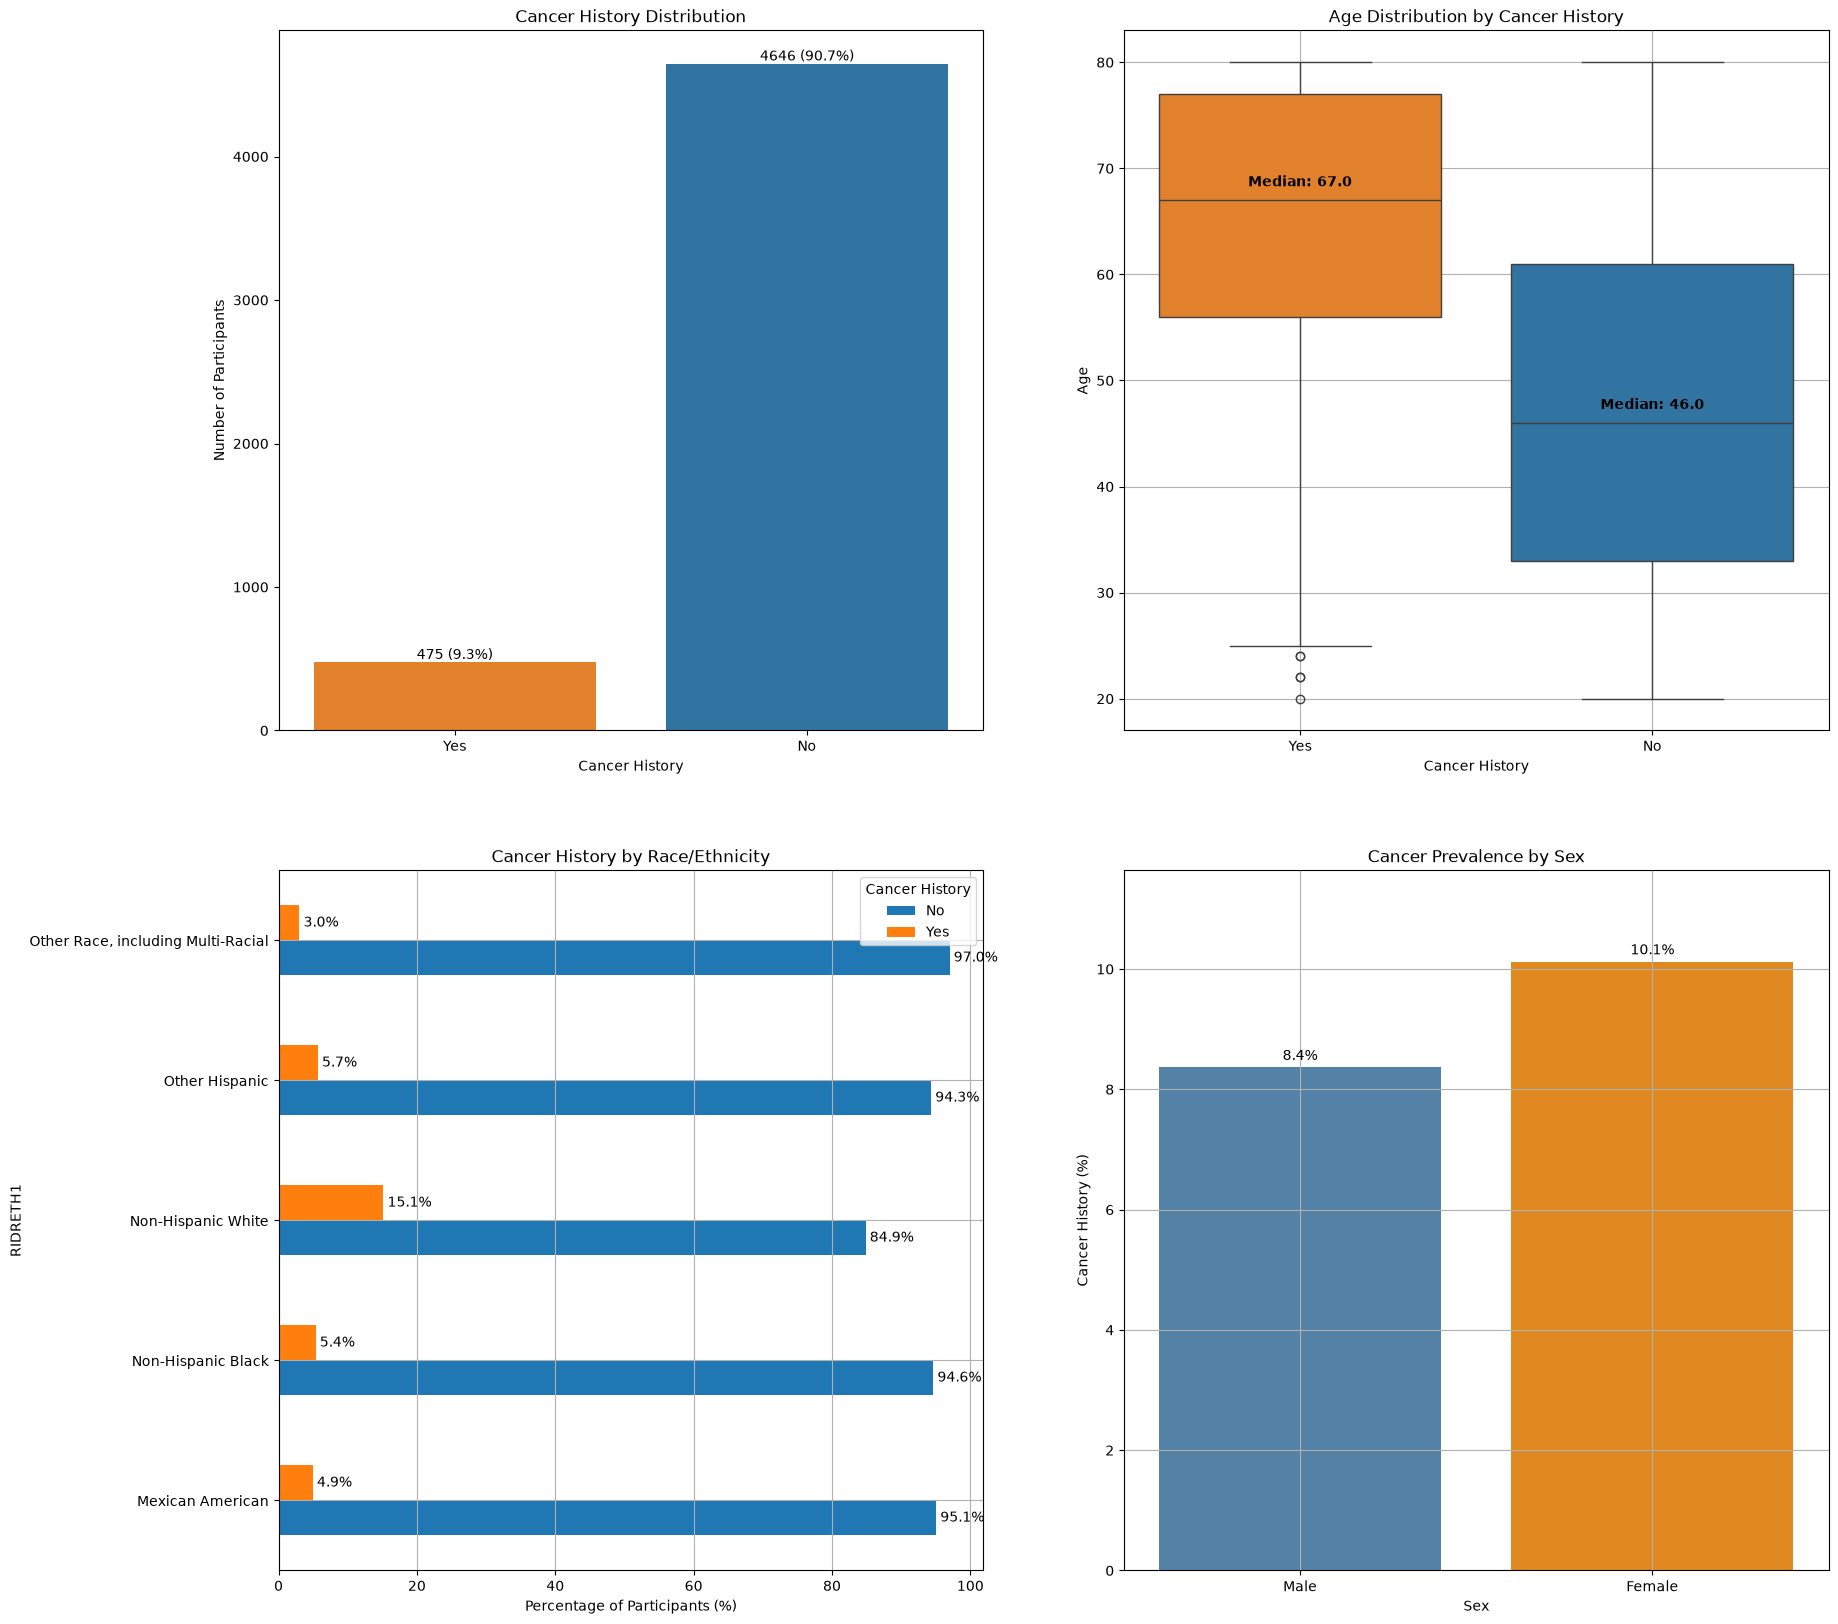

In [11]:
display(fig)

## Observations

### 1. Cancer History Distribution

- Out of **5,121 participants**, 475 (9.3%) reported a history of cancer, while 4,646 (90.7%) reported no history of cancer.
- The dataset therefore contains a considerably larger group of participants without a reported cancer history.

### 2. Age Distribution by Cancer History

- Participants reporting a history of cancer had a median age of **67 years**, compared with **46 years** among participants without a cancer history.
- This represents a difference of **21 years** between the two groups.
- The box plot shows that participants with a cancer history are generally older than those without one.
- Age appears to be an important factor to consider in subsequent statistical analyses because cancer history differs considerably across the age distributions.

### 3. Cancer History by Race/Ethnicity

- The highest proportion of reported cancer history was observed among **Non-Hispanic White participants (15.1%)**.
- Other Hispanic participants had a cancer-history proportion of 5.7%, followed by Non-Hispanic Black participants (5.4%) and Mexican American participants (4.9%).
- The lowest proportion was observed among Other Race, including Multi-Racial participants (3.0%).
- These percentages represent cancer-history proportions within each racial/ethnic group, rather than the distribution of all cancer cases across groups.

### 4. Cancer Prevalence by Sex

- Female participants had a higher reported cancer prevalence (**10.1%**) than male participants (**8.4%**).
- In terms of participant counts, 269 females and 206 males reported a history of cancer.
- The difference in prevalence is approximately **1.7 percentage points**.

### Overall Interpretation

- Approximately 9.3% of participants reported a history of cancer.
- Participants with a cancer history were substantially older than those without one.
- Differences in reported cancer prevalence were also observed across racial/ethnic groups and between sexes.
- Age may influence these observed differences, so subsequent analyses should consider age as a potential confounding variable.
- These visualizations describe associations within the study sample and do not establish causal relationships.

# Smoking & Alcohol History vs Cancer History.

In [12]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(24, 20)
)
axes = np.array(axes).ravel()
plt.close(fig)

## Smoking

In [13]:
# Stacked-Bar Graph
# The smoking-history variable is categorical (`ever smoked 100+ cigarettes: Yes/No`), and each bar has two categories representing MCQ220 (has Cancer or Not)
# Hence, the stacked bar graph shows the composition of cancer history in each smoking group while controlling for different group sizes. 

smoking_data = cancer_data.copy()
smoking_data["SMQ020"] = smoking_data["SMQ020"].map({
    1: "Yes",
    2: "No"
})
smoking_cancer = pd.crosstab(
    smoking_data["SMQ020"],
    smoking_data["MCQ220"],
    normalize="index"
) * 100

smoking_cancer = smoking_cancer.reindex(
    index=["No", "Yes"],
    columns=["No", "Yes"]
)
print(smoking_cancer)

smoking_cancer.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    color=["steelblue", "darkorange"]
)

for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%.1f%%",
        label_type="center",
        fontsize=9
    )

axes[0].set_title("Cancer History by Lifetime Smoking")
axes[0].set_xlabel("Ever smoked 100+ cigarettes?")
axes[0].set_ylabel("Participants (%)")
axes[0].set_xticklabels(["Never", "Ever"], rotation=0)
axes[0].legend(
    title="Reported Cancer History",
    labels=["No cancer", "Cancer"],
    loc="upper right"
)
axes[0].grid(axis="y", linestyle=":", alpha=0.5)
axes[0].set_axisbelow(True)

plt.tight_layout()

MCQ220         No        Yes
SMQ020                      
No      92.454136   7.545864
Yes     88.485663  11.514337


<Figure size 640x480 with 0 Axes>

## Current Smoking Status vs Cancer History

In [14]:
# Bar Graph
# Current smoking status has three categories, and each category is split into cancer-history `Yes` and `No` percentages. 
# Side-by-side bars make the two cancer-history proportions easy to compare within each smoking-status category

smoking_data["SMQ040"] = smoking_data["SMQ040"].map({
    1: "Every day",
    2: "Some days",
    3: "Not at all"
})
smoking_status = pd.crosstab(smoking_data["SMQ040"], smoking_data["MCQ220"], normalize="index") * 100

smoking_status.plot(kind="bar", ax=axes[1], color=["steelblue", "darkorange"])

for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=8
    )

axes[1].set_title("Cancer History by Current Smoking Status")
axes[1].set_xlabel("Current Smoking Frequency")
axes[1].set_ylabel("Participants (%)")
axes[1].legend(
    title="Cancer History",
    labels=["No cancer", "Cancer"],
    loc="upper right"
)
axes[1].grid(axis="y", linestyle=":", alpha=0.5)
axes[1].set_axisbelow(True)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Alcohol Use

In [15]:
alcohol_data = cancer_data.copy()

alcohol_labels = {
    1: "Yes",
    2: "No"
}

alcohol_data["ALQ101"] = alcohol_data["ALQ101"].map(alcohol_labels)

In [16]:
# Stacked-Bar Graph
# Similar to the Smoking History vs Cancer History case, here ALQ101 is a categorial variable (yes/no) and each category is splitted as per MCQ220 (Cancer history), hence stacked-bar graph is suitable

alcohol_cancer = pd.crosstab(
    alcohol_data["ALQ101"],
    alcohol_data["MCQ220"],
    normalize="index"
) * 100

alcohol_cancer.plot(
    kind="bar",
    stacked=True,
    ax=axes[2],
    color=["steelblue", "darkorange"]
)

for container in axes[2].containers:
    axes[2].bar_label(
        container,
        fmt="%.1f%%",
        label_type="center",
        fontsize=9
    )

axes[2].set_title("Cancer History by Alcohol Use")
axes[2].set_xlabel("Ever had at least 12 alcoholic drinks in one year?")
axes[2].set_ylabel("Participants (%)")
axes[2].legend(
    title="Reported Cancer History",
    labels=["No cancer", "Cancer"],
    loc="upper right"
)
axes[2].grid(axis="y", linestyle=":", alpha=0.5)
axes[2].set_axisbelow(True)
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Alcohol Frequency

In [17]:
# Cancer prevalence by alcohol consumption frequency
alcohol_cancer_freq = pd.crosstab(
    alcohol_data["ALQ120Q"],
    alcohol_data["MCQ220"],
    normalize="index"
) * 100

# Keep only the cancer percentage
cancer_percent = alcohol_cancer_freq["Yes"]

# Plot
cancer_percent.plot(kind="bar",ax=axes[3],color="darkorange",width=0.7)

for container in axes[3].containers:
    axes[3].bar_label(container, fmt="%.1f%%", rotation=90, padding=4, fontsize=8)

axes[3].set_title("Cancer History by Alcohol Consumption Frequency")
axes[3].set_xlabel("Alcohol Consumption Frequency Code")
axes[3].set_ylabel("Participants Reporting Cancer (%)")
axes[3].grid(axis="y", linestyle=":", alpha=0.5)
axes[3].set_axisbelow(True)
axes[3].tick_params(axis="x", rotation=90)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [18]:
cancer_data["ALQ120Q"].isna().sum()

np.int64(1097)

In [19]:
print(alcohol_data["ALQ120Q"].value_counts().sort_index().to_string())

ALQ120Q
0.0      796
1.0      932
2.0      801
3.0      463
4.0      274
5.0      243
6.0      125
7.0      172
8.0       22
9.0        4
10.0      63
11.0       1
12.0      22
13.0       1
14.0       5
15.0      20
16.0       2
18.0       1
20.0      20
24.0       4
25.0       4
28.0       2
30.0      20
35.0       1
40.0       2
45.0       1
52.0       1
61.0       1
80.0       2
90.0       1
96.0       1
100.0      2
112.0      1
120.0      1
160.0      1
180.0      1
182.0      1
200.0      1
300.0      1
305.0      1
350.0      1
365.0      6


## Visualization

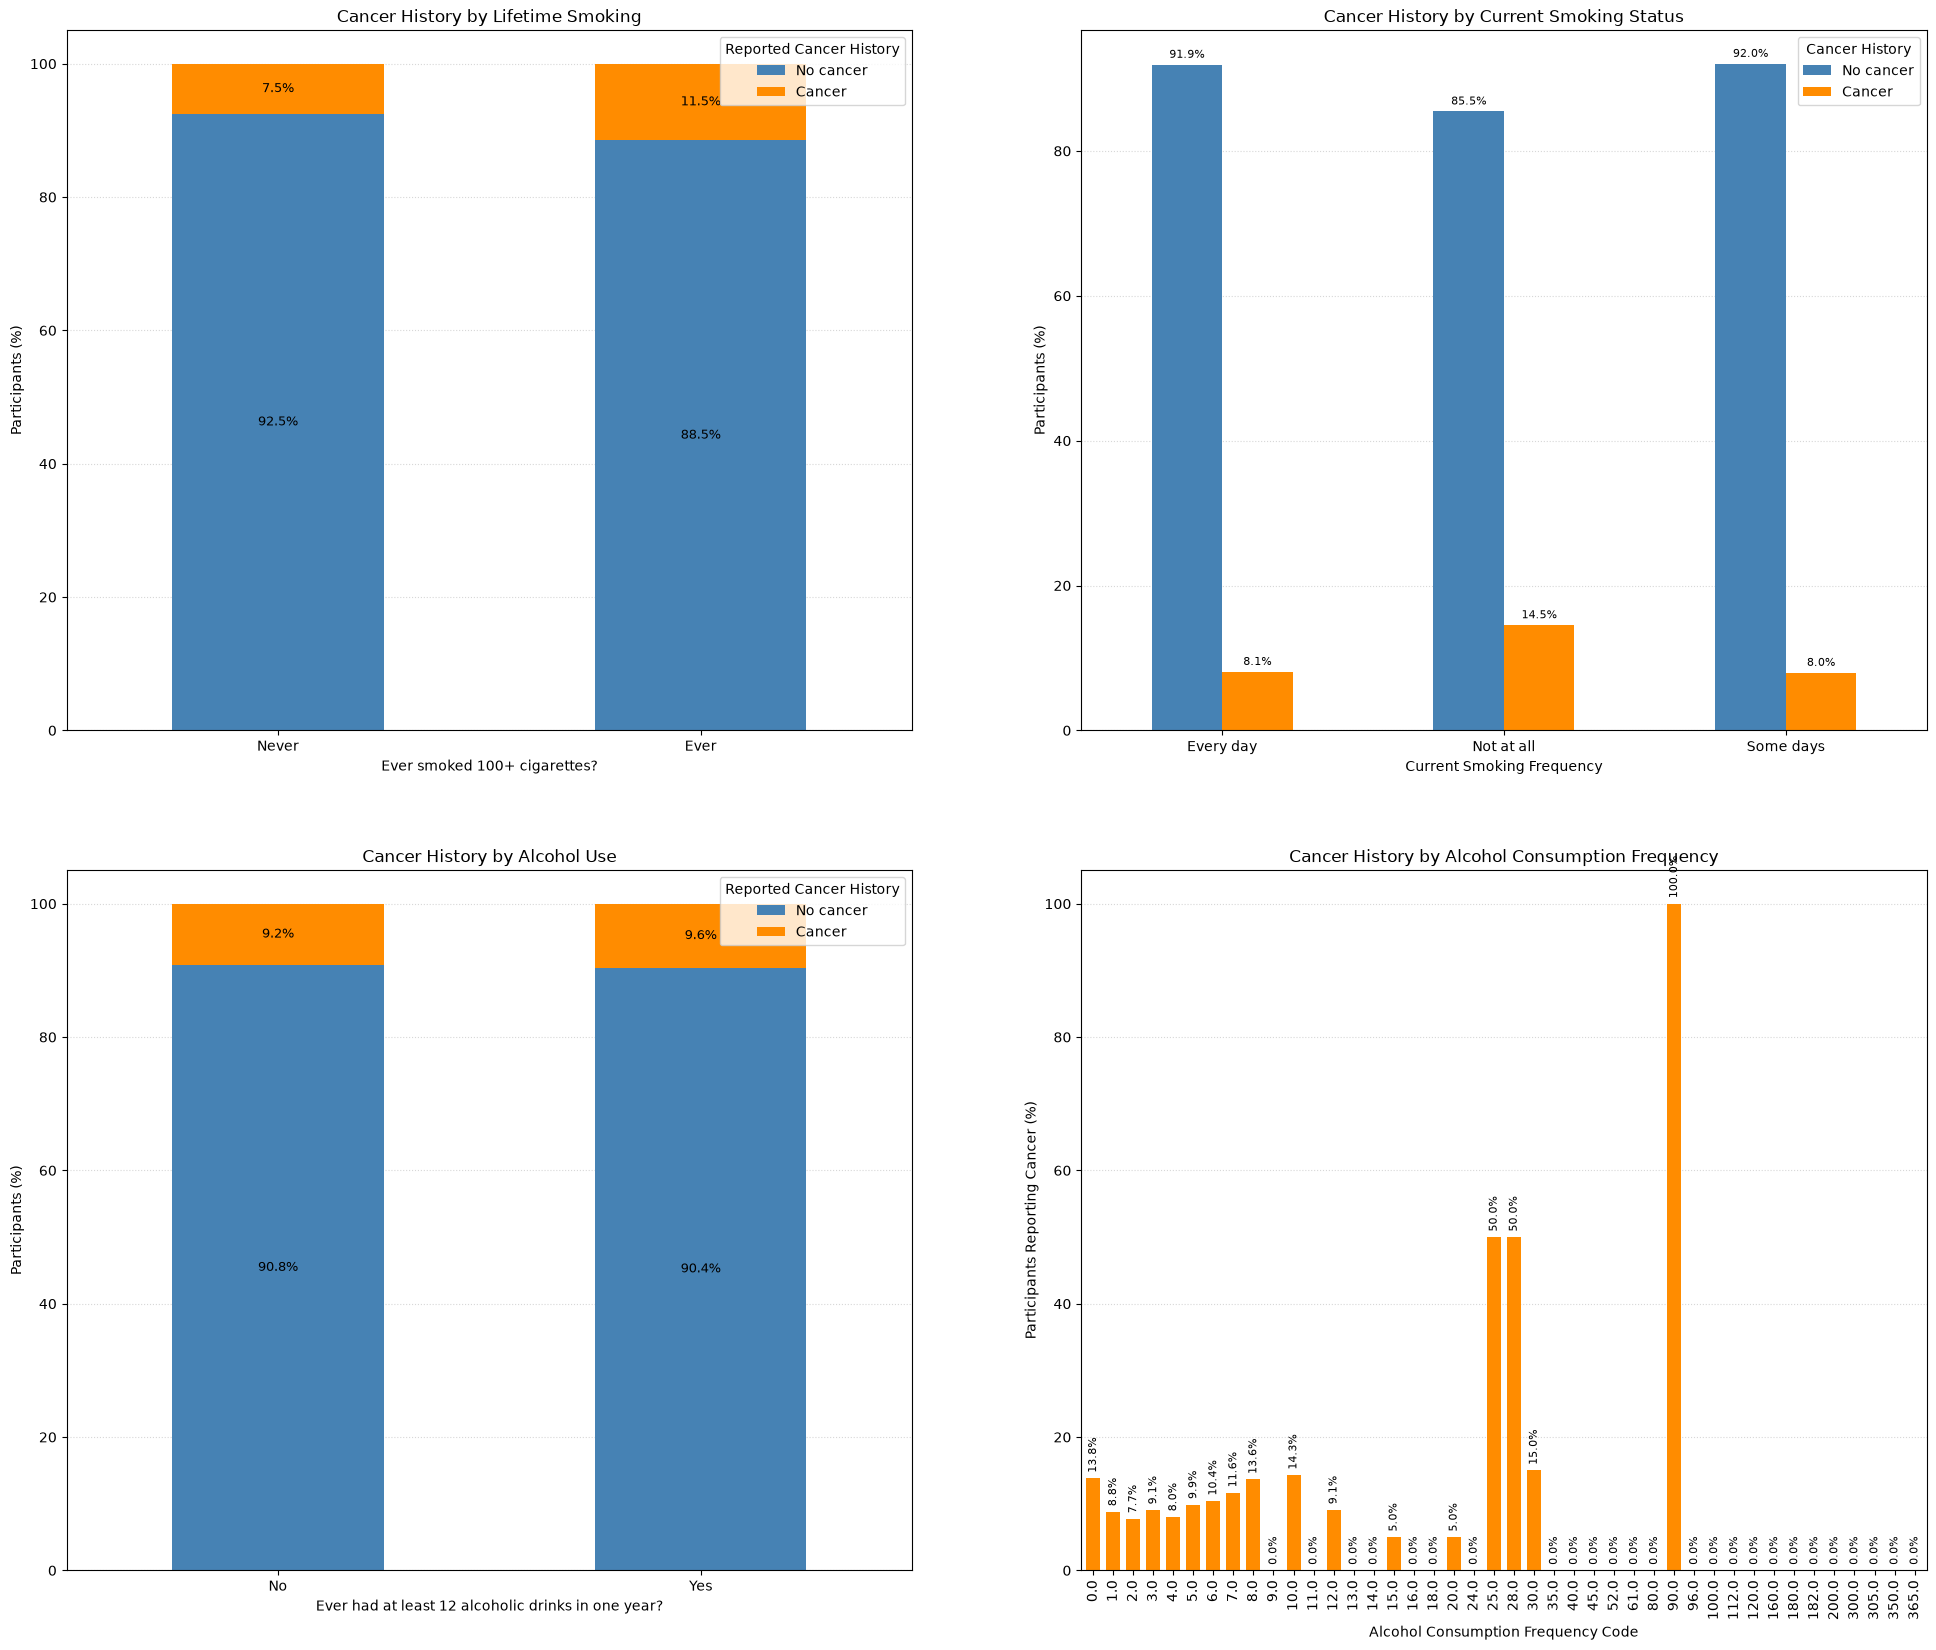

In [20]:
display(fig)

## Observations

### 1. Lifetime Smoking History

- Participants who had smoked at least 100 cigarettes during their lifetime had a cancer-history proportion of **11.5%**, compared with **7.5%** among those who had never smoked 100 cigarettes.
- This represents a difference of approximately **4 percentage points**.
- The observed results suggest an association between lifetime cigarette-smoking history and reported cancer history.

### 2. Current Smoking Status

- Participants who reported smoking every day had a cancer-history proportion of **8.1%**, while those who smoked on some days had a proportion of **8.0%**.
- The highest cancer-history proportion (**14.5%**) was observed among participants who reported not currently smoking.
- The current smoking-status question applies to participants who had previously smoked at least 100 cigarettes. Therefore, the "Not at all" category represents former smokers rather than people who have never smoked.
- Differences in age, previous smoking exposure, and smoking cessation may influence the observed results.

### 3. Alcohol Consumption History

- Participants who reported consuming at least 12 alcoholic drinks in any one year had a cancer-history proportion of **9.6%**, compared with **9.2%** among those who did not.
- The difference of approximately **0.4 percentage points** indicates very similar cancer-history proportions between the two groups.
- This variable represents historical alcohol consumption and should not be interpreted as a measure of current drinking behaviour.

### 4. Alcohol Consumption Frequency

- Alcohol consumption frequency is represented by two variables: `ALQ120Q` (frequency quantity) and `ALQ120U` (unit of frequency).
- The frequency may be reported per week, month, or year.
- The raw frequency values cannot be directly compared without accounting for their associated units.
- The current frequency visualization is therefore excluded from interpretation until the values are converted into a common annual frequency measure.

### Overall Interpretation

- A higher cancer-history proportion was observed among participants who had smoked at least 100 cigarettes during their lifetime.
- Former smokers showed a higher cancer-history proportion than current smokers in the descriptive comparison.
- Alcohol consumption history showed very similar cancer-history proportions between the Yes and No groups.
- Age and previous lifestyle exposure may influence these observed differences.
- These descriptive findings identify potential associations but do not establish causal relationships.

 # Physical Activity

In [21]:
activity_data = cancer_data.copy()
activity_data["PAQ650"] = activity_data["PAQ650"].map({
    1: "Yes",
    2: "No"
})

In [22]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(20, 15)
)
axes = np.array(axes).ravel()
plt.close(fig)

## Vigorous Activity

In [23]:
# Stacked-Bar Garph
# Vigorous recreational activity is a yes/no category, and we need to compare cancer-history proportion within each category
# Hence, stacked-bar graph is suitable for this task

activity_cancer = pd.crosstab(
    activity_data["PAQ650"],
    activity_data["MCQ220"],
    normalize="index"
) * 100

activity_cancer = activity_cancer.reindex(["Yes", "No"])

activity_cancer.plot(
    kind="bar",
    stacked=True,
    ax=axes[0],
    color=["steelblue", "darkorange"]
)

for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%.1f%%",
        label_type="center",
        fontsize=9
    )

axes[0].set_title("Cancer History by Vigorous Recreational Activity")
axes[0].set_xlabel("Vigorous Recreational Activity")
axes[0].set_ylabel("Participants (%)")
axes[0].legend(
    title="Cancer History",
    labels=["No cancer", "Cancer"],
    loc="upper right"
)
axes[0].grid(True)
axes[0].set_axisbelow(True)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Moderate Work Activity

In [24]:
# Stacked-Bar Graph
# Similar to the vigorous activity, his field is also categorial

activity_data["PAQ620"] = activity_data["PAQ620"].map({
    1: "Yes",
    2: "No"
})

activity_cancer = pd.crosstab(
    activity_data["PAQ620"],
    activity_data["MCQ220"],
    normalize="index"
) * 100

activity_cancer = activity_cancer.reindex(["Yes", "No"])

activity_cancer.plot(kind="bar",stacked=True, ax=axes[1],color=["steelblue", "darkorange"])

for container in axes[1].containers:
    axes[1].bar_label(container,fmt="%.1f%%",label_type="center", fontsize=9)

axes[1].set_title("Cancer History by Moderate Work Activity")
axes[1].set_xlabel("Moderate Work Activity")
axes[1].set_ylabel("Participants (%)")
axes[1].legend(title="Cancer History", labels=["No cancer", "Cancer"], loc="upper right")
axes[1].grid(True)
axes[1].set_axisbelow(True)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Use of Walking / Cycling for Transportation

In [25]:
# Bar Graph
# The walking/cycling response is categorical, and the grouped bars place cancer-history percentages side by side within each response. 
# This makes the difference between `Yes` and `No` cancer-history proportions easier to compare directly than reading the segments of a stacked bar.

activity_data["PAQ635"] = activity_data["PAQ635"].map({
    1: "Yes",
    2: "No"
})

activity_cancer = pd.crosstab(
    activity_data["PAQ635"],
    activity_data["MCQ220"],
    normalize="index"
) * 100

activity_cancer = activity_cancer.reindex(["Yes", "No"])

activity_cancer.plot(
    kind="bar",
    stacked=False,
    ax=axes[2],
    color=["steelblue", "darkorange"],
    width=0.7
)

for container in axes[2].containers:
    axes[2].bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[2].set_title("Cancer History by Walking/Cycling for Transportation")
axes[2].set_xlabel("Walks/Cycles for Transportation")
axes[2].set_ylabel("Participants (%)")
axes[2].legend(title="Cancer History", loc="upper right")
axes[2].grid(True)
axes[2].set_axisbelow(True)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

In [26]:
activity_vars = {
    "Vigorous recreational": "PAQ650",
    "Moderate work": "PAQ620",
    "Walking/Cycling": "PAQ635"
}

cancer_yes = []
cancer_no = []

for label, col in activity_vars.items():
    temp = df[[col, "MCQ220"]].dropna()

    active = temp[temp[col] == 1]
    inactive = temp[temp[col] == 2]

    cancer_yes.append(
        (active["MCQ220"] == 1).mean() * 100
    )

    cancer_no.append(
        (inactive["MCQ220"] == 1).mean() * 100
    )

x = np.arange(len(activity_vars))
width = 0.35

ax = axes[3]

bars1 = ax.bar(
    x - width/2, cancer_yes, width,
    label="Activity: Yes"
)

bars2 = ax.bar(
    x + width/2, cancer_no, width,
    label="Activity: No"
)

ax.set_title("Cancer Prevalence by Physical Activity Type")
ax.set_ylabel("Cancer History (%)")
ax.set_xticks(x)
ax.set_xticklabels(activity_vars.keys(), rotation=15)
ax.legend(loc="upper right")

ax.bar_label(bars1, fmt="%.1f%%", padding=2, fontsize=8)
ax.bar_label(bars2, fmt="%.1f%%", padding=2, fontsize=8)

ax.grid(axis="y", alpha=0.3)

## Visualization

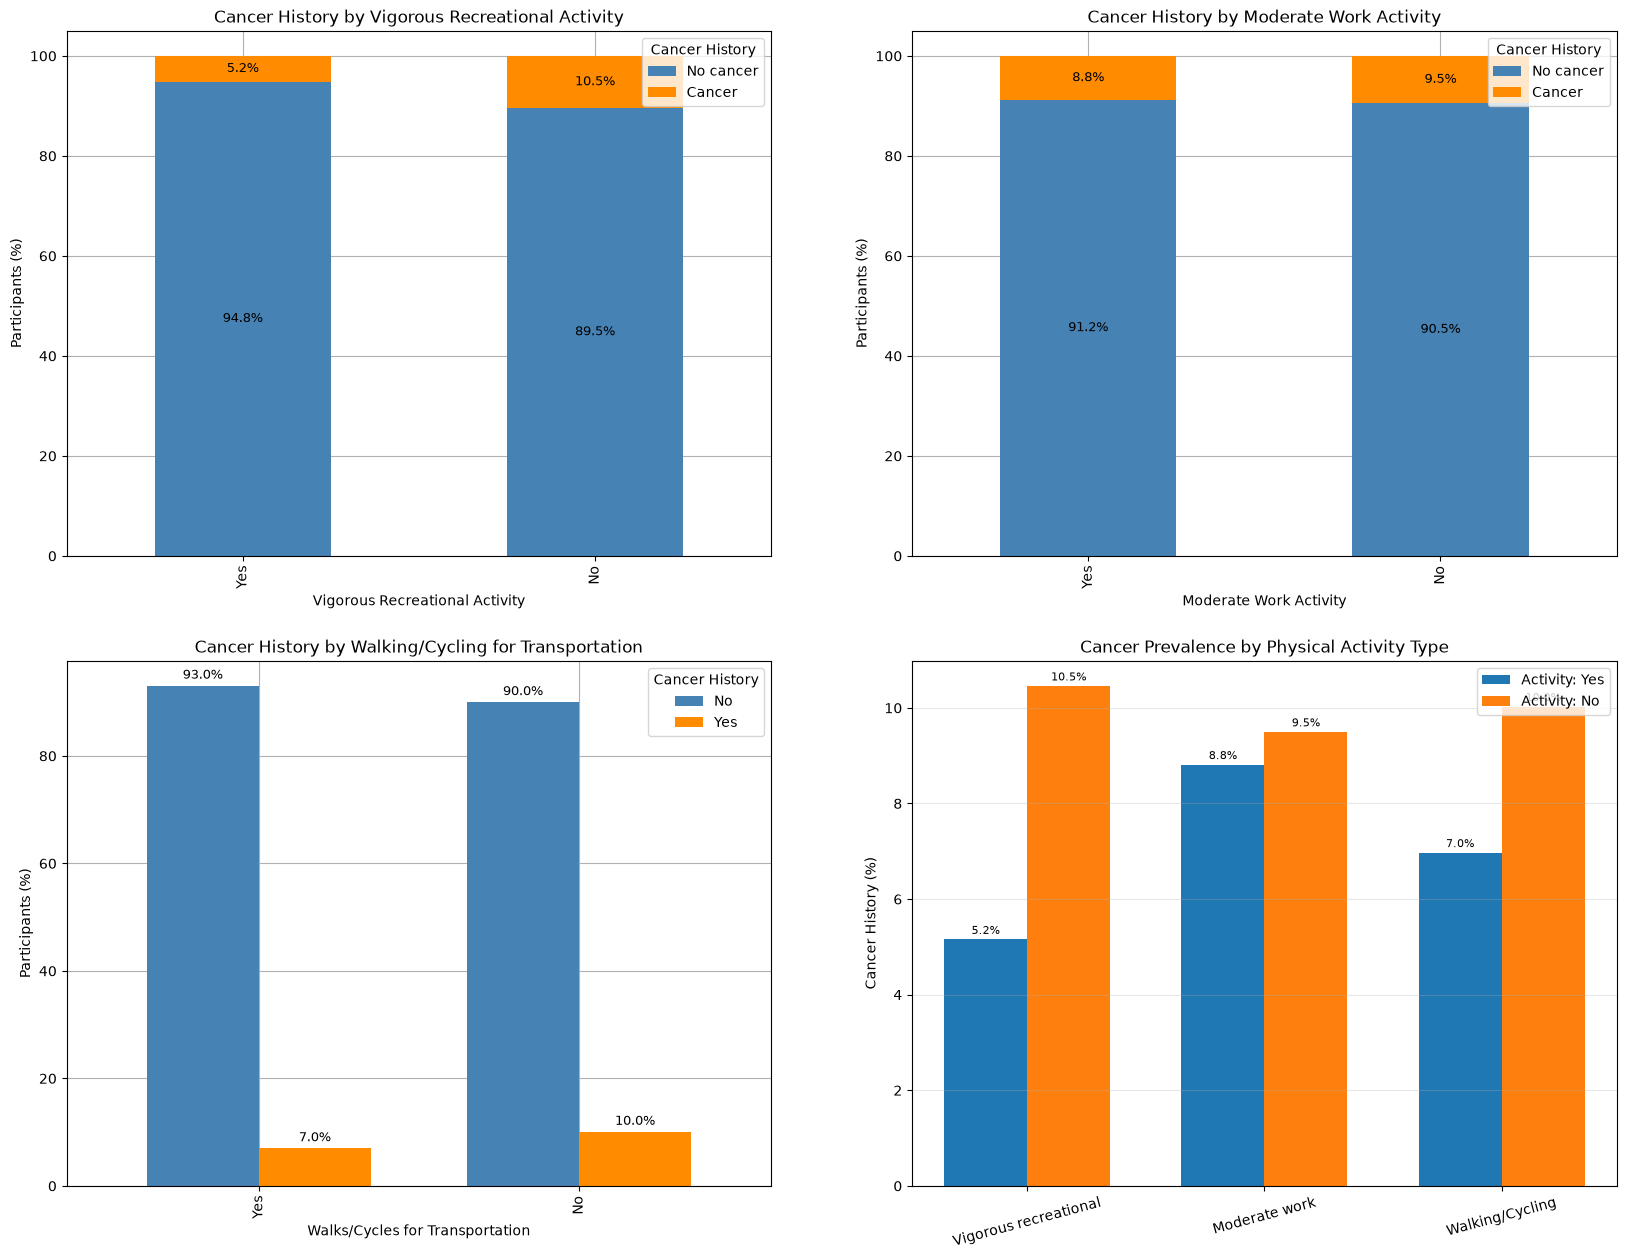

In [27]:
display(fig)

## Observations — Physical Activity and Cancer History

### 1. Vigorous Recreational Activity

- Participants who reported vigorous recreational activity had a cancer-history proportion of **5.2%**, compared with **10.5%** among those who did not report such activity.
- This represents a difference of approximately **5.3 percentage points**, making it the largest observed difference among the three physical activity categories.

### 2. Moderate Work Activity

- Participants reporting moderate work-related physical activity had a cancer-history proportion of **8.8%**, compared with **9.5%** among those who did not.
- The difference between the two groups is relatively small, at approximately **0.7 percentage points**.

### 3. Walking/Cycling for Transportation

- Participants who reported walking or cycling for transportation had an approximate cancer-history proportion of **7%**.
- Participants who did not report this activity had an approximate proportion of **10%**.
- This indicates a difference in reported cancer history between the two groups.

### Overall Interpretation

- Lower cancer-history proportions were observed among participants reporting all three forms of physical activity.
- The largest difference was observed for vigorous recreational activity.
- Moderate work-related activity showed only a small difference.
- These findings suggest potential associations between physical activity and reported cancer history.
- Age and other demographic or lifestyle characteristics may influence these differences and should be considered in subsequent statistical analyses.
- These descriptive comparisons do not establish that physical activity prevents cancer or causes a reduction in cancer risk.

# Health Measurements and Dietary Factors

In [28]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(20, 15)
)
axes = np.array(axes).ravel()
plt.close(fig)

In [29]:
health_data = cancer_data.copy()

## BMI Distribution

In [30]:
column_data["BMXBMI"]

{'name': 'BMI',
 'description': 'Body Mass Index.',
 'missing_values': 0,
 'missing_proportion': 0.0}

In [31]:
# Violin Plot
# BMI is continuous, and the violin plot will easily show the distribution's shape/density in each cancer-history group, with quartiles marked inside. 
# This can reveal whether values cluster around one region or have a different spread

bmi_data = health_data[health_data["BMXBMI"].notna()].copy()

sns.violinplot(
    data=health_data,
    x="MCQ220",
    y="BMXBMI",
    order=["No", "Yes"],
    hue="MCQ220",
    hue_order=["No", "Yes"],
    palette=["steelblue", "darkorange"],
    legend=False,
    inner="box",
    ax=axes[0],
    cut=0
)

axes[0].set_title("BMI Distribution by Cancer History")
axes[0].set_xlabel("Cancer History")
axes[0].set_ylabel("BMI (kg/m²)")
axes[0].grid(True)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Blood Glucose Level

In [32]:
column_data["LBXSGL"]

{'name': 'Blood Glucose',
 'description': 'Blood glucose.',
 'missing_values': 0,
 'missing_proportion': 0.0}

In [33]:
# Box Plot
# Similar to the BMI distribution, blood glucose level is continuous and violin plot will reveal many useful infromations

glucose_data = health_data[health_data["LBXSGL"].notna()].copy()

sns.violinplot(
    data=glucose_data,
    x="MCQ220",
    y="LBXSGL",
    order=["No", "Yes"],
    hue="MCQ220",
    hue_order=["No", "Yes"],
    palette=["steelblue", "darkorange"],
    legend=False,
    inner="box",
    ax=axes[1],
    cut=0
)

axes[1].set_title("Blood Glucose Level by Cancer History")
axes[1].set_xlabel("Cancer History")
axes[1].set_ylabel("Blood Glucose (mg/dL)")
axes[1].grid(True)
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

## Dietary Fibre Intake

In [34]:
column_data["DR1TFIBE"]

{'name': 'Fiber Intake',
 'description': 'Dietary fibre intake.',
 'missing_values': 400,
 'missing_proportion': 7.810974419058778}

In [35]:
# Histogram
# The x and y axis both are continuous, and we need to show data based on the bins on the x axis, hence historgram is suitable

fibre_data = health_data[health_data["DR1TFIBE"].notna()].copy()

sns.histplot(
    data=fibre_data,
    x="DR1TFIBE",
    hue="MCQ220",
    hue_order=["No", "Yes"],
    bins=30,
    stat="percent",
    common_norm=False,
    element="step",
    fill=False,
    palette=["steelblue", "darkorange"],
    ax=axes[2]
)

axes[2].set_title("Dietary Fibre Intake by Cancer History")
axes[2].set_xlabel("Daily Dietary Fibre Intake (g)")
axes[2].set_ylabel("Participant Count  (%)")
axes[2].grid(True)
axes[2].legend(title="Cancer History", labels=["No", "Yes"])
axes[2].set_axisbelow(True)

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

## Cholestrol

In [36]:
# Total Cholesterol Distribution by Cancer History
cholesterol_data = health_data[health_data["LBXSCH"].notna()].copy()

sns.histplot(
    data=cholesterol_data,
    x="LBXSCH",
    hue="MCQ220",
    hue_order=["No", "Yes"],
    bins=30,
    stat="percent",
    common_norm=False,
    element="step",
    fill=False,
    palette=["steelblue", "darkorange"],
    ax=axes[3]
)

axes[3].set_title("Total Cholesterol by Cancer History")
axes[3].set_xlabel("Total Cholesterol (mg/dL)")
axes[3].set_ylabel("Number of Participants  (%)")
axes[3].grid(True)
axes[2].legend(title="Cancer History", labels=["No", "Yes"])
axes[3].set_axisbelow(True)

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

## Sugar Intake

In [37]:
column_data["DR1TSUGR"]

{'name': 'Sugar Intake',
 'description': 'Total sugar intake.',
 'missing_values': 400,
 'missing_proportion': 7.810974419058778}

In [38]:
# Sugar Intake by Cancer History
sns.histplot(
    data=health_data[health_data["DR1TSUGR"].notna()].copy(),
    x="DR1TSUGR",
    hue="MCQ220",
    hue_order=["No", "Yes"],
    bins=30,
    common_norm=False,
    element="step",
    stat="percent",
    fill=False,
    palette=["steelblue", "darkorange"],
    ax=axes[4]
)

axes[4].set_title("Sugar Intake by Cancer History")
axes[4].set_xlabel("Daily Sugar Intake (g)")
axes[4].set_ylabel("Number of Participants  (%)")
axes[4].grid()
axes[2].legend(title="Cancer History", labels=["No", "Yes"])
axes[4].set_axisbelow(True)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Protein Intake

In [39]:
# Protein Intake by Cancer History
sns.violinplot(
    data=health_data[health_data["DR1TPROT"].notna()],
    x="MCQ220",
    y="DR1TPROT",
    order=["No", "Yes"],
    hue="MCQ220",
    hue_order=["No", "Yes"],
    palette=["steelblue", "darkorange"],
    legend=False,
    inner="box",
    ax=axes[5],
    cut=0
)

axes[5].set_title("Protein Intake by Cancer History")
axes[5].set_xlabel("Cancer History")
axes[5].set_ylabel("Protein Intake (g/day)")
axes[5].grid(True)
axes[5].set_axisbelow(True)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Total Fat

In [40]:
sns.violinplot(
    data=health_data[health_data["DR1TTFAT"].notna()],
    x="MCQ220",
    y="DR1TTFAT",
    order=["No", "Yes"],
    hue="MCQ220",
    hue_order=["No", "Yes"],
    palette=["steelblue", "darkorange"],
    legend=False,
    inner="box",
    ax=axes[6],
    cut=0
)

axes[6].set_title("Total Fat Intake by Cancer History")
axes[6].set_xlabel("Cancer History")
axes[6].set_ylabel("Total Fat Intake (g/day)")
axes[6].grid(True)
axes[6].set_axisbelow(True)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Carbohydrate Intake

In [41]:
sns.violinplot(
    data=health_data[health_data["DR1TCARB"].notna()],
    x="MCQ220",
    y="DR1TCARB",
    order=["No", "Yes"],
    hue="MCQ220",
    hue_order=["No", "Yes"],
    palette=["steelblue", "darkorange"],
    inner="box",
    legend=False,
    ax=axes[7],
    cut=0
)

axes[7].set_title("Carbohydrate Intake by Cancer History")
axes[7].set_xlabel("Cancer History")
axes[7].set_ylabel("Carbohydrate Intake (g/day)")
axes[7].grid(True)
axes[7].set_axisbelow(True)

plt.tight_layout()

<Figure size 640x480 with 0 Axes>

## Visualization

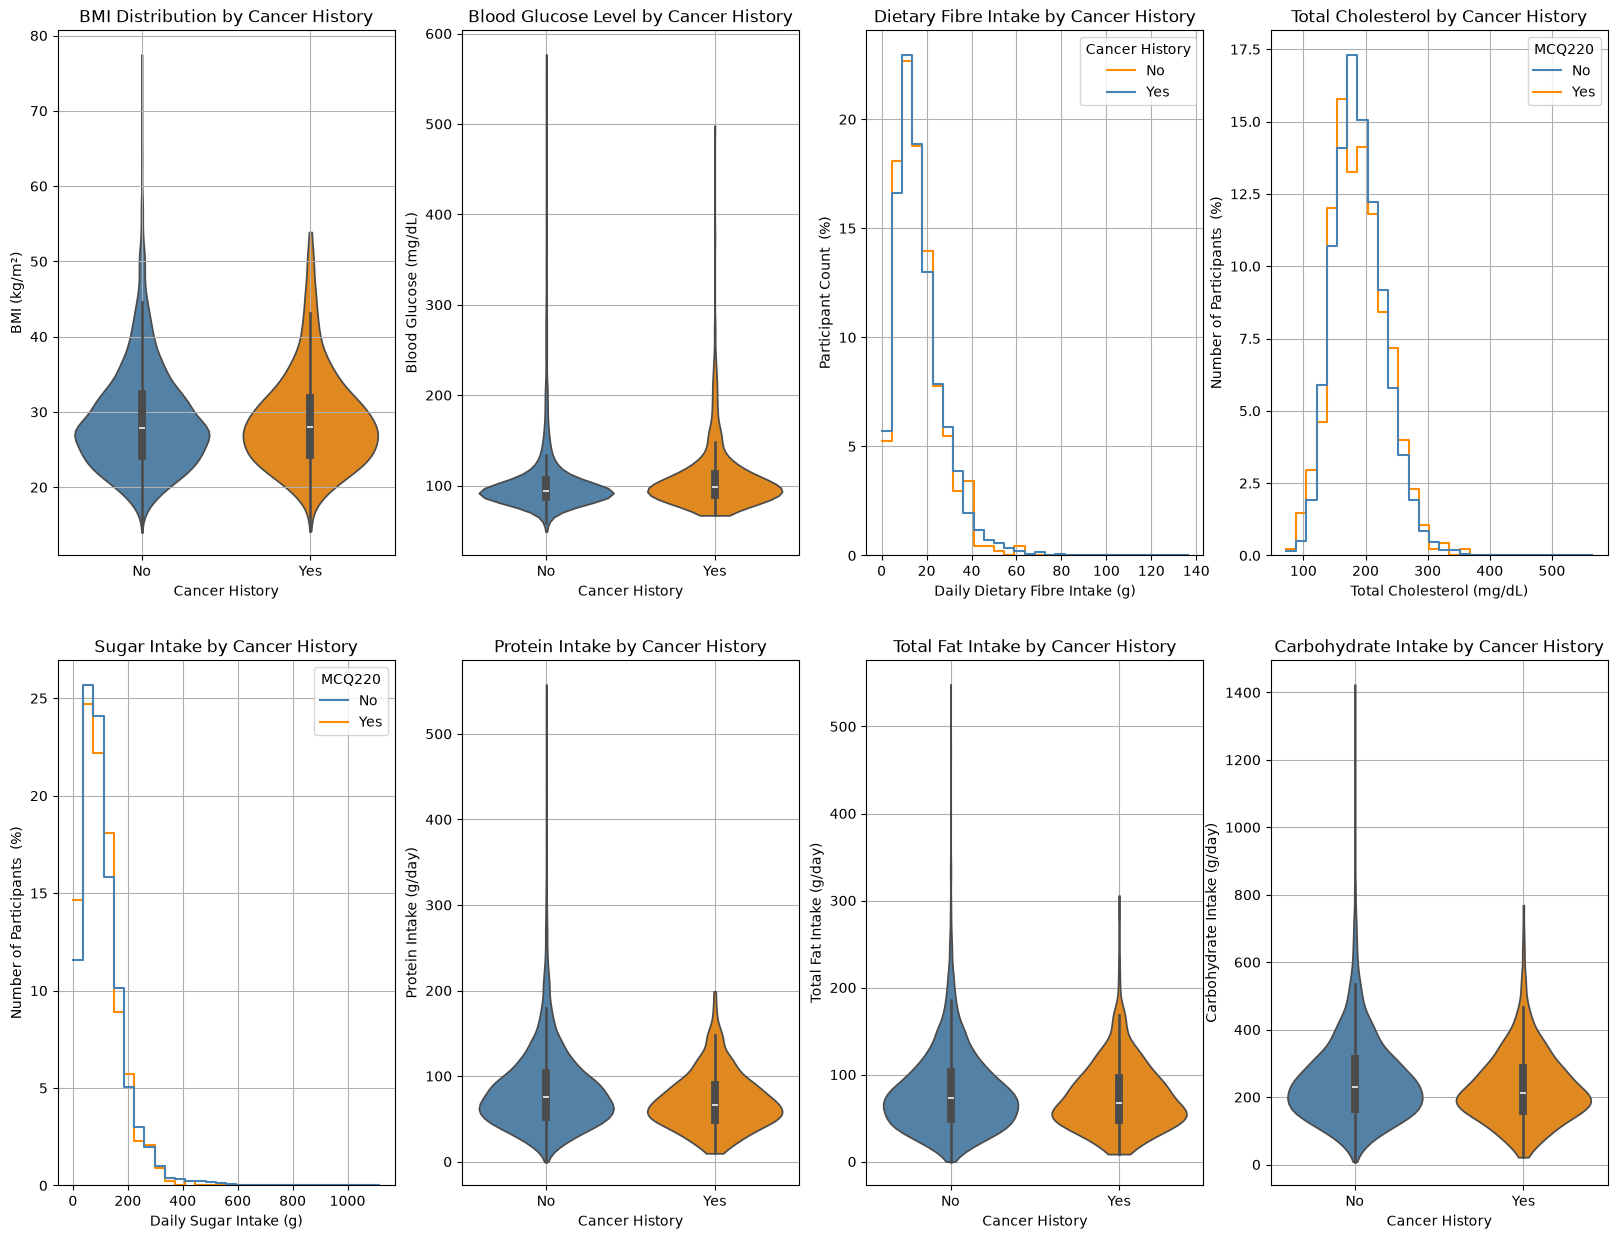

In [42]:
display(fig)

## Blood Pressure Visualization

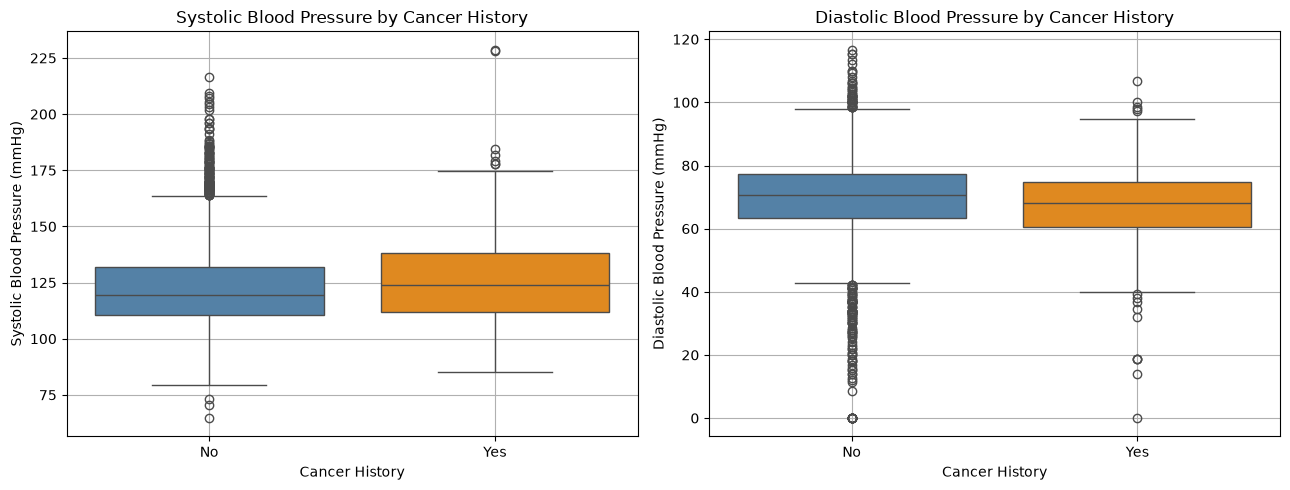

In [43]:
# Blood Pressure Analysis
bp_columns = ["SBP_mean", "DBP_mean"]

bp_data = health_data[["MCQ220"] + bp_columns].copy()

# Convert blood pressure columns to numeric
for column in bp_columns:
    bp_data[column] = pd.to_numeric(bp_data[column], errors="coerce")

# Create side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=bp_data.dropna(subset=["SBP_mean", "MCQ220"]),
    x="MCQ220",
    y="SBP_mean",
    hue="MCQ220",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "darkorange"},
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Systolic Blood Pressure by Cancer History")
axes[0].set_xlabel("Cancer History")
axes[0].set_ylabel("Systolic Blood Pressure (mmHg)")

sns.boxplot(
    data=bp_data.dropna(subset=["DBP_mean", "MCQ220"]),
    x="MCQ220",
    y="DBP_mean",
    hue="MCQ220",
    order=["No", "Yes"],
    hue_order=["No", "Yes"],
    palette={"No": "steelblue", "Yes": "darkorange"},
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Diastolic Blood Pressure by Cancer History")
axes[1].set_xlabel("Cancer History")
axes[1].set_ylabel("Diastolic Blood Pressure (mmHg)")

axes[0].grid(True)
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Observations — Health Measurements and Dietary Factors

### 1. BMI Distribution by Cancer History

- The BMI distributions of participants with and without a reported cancer history show considerable overlap.
- Both groups have similar central BMI values, with most observations concentrated approximately between 22 and 33 kg/m².
- No substantial visual difference is apparent between the two groups.
- Overall, BMI alone does not appear to clearly distinguish participants with a cancer history from those without one.


### 2. Blood Glucose Level by Cancer History

- Most participants in both groups have blood glucose levels concentrated approximately between 80 and 110 mg/dL.
- Participants with a reported cancer history appear to have a slightly higher median glucose level.
- Both distributions have extended upper tails, indicating the presence of participants with considerably higher glucose measurements.
- The substantial overlap suggests that blood glucose levels do not show a pronounced difference between the two groups based on this visualization.

### 3. Dietary Fibre Intake by Cancer History

- Most participants in both groups report relatively low daily dietary fibre intake, with the majority of observations concentrated below approximately 30 g/day.
- The distributions are right-skewed, with a smaller number of participants reporting substantially higher fibre intake.
- Considerable overlap is observed between the two cancer-history groups.
- Extreme values are retained because they may represent genuine dietary observations.
- The dietary measurements are based on the first day's dietary recall and may not represent participants' usual long-term intake.


### 4. Total Cholesterol by Cancer History

- The total cholesterol distributions of participants with and without a cancer history overlap considerably.
- Most observations are concentrated approximately between 150 and 250 mg/dL.
- Both groups show a similar overall distribution, without a clearly distinguishable separation.
- A smaller number of participants have substantially higher cholesterol measurements.
- Overall, total cholesterol does not show an obvious difference between the two groups based on the descriptive visualization.

### 5. Sugar Intake by Cancer History

- Most participants in both groups have daily sugar intake concentrated approximately below 200 g.
- The distributions are strongly right-skewed, with a smaller number of participants reporting considerably higher sugar intake.
- The two distributions overlap substantially, suggesting no clear visual difference in sugar intake between the cancer-history groups.
- Extreme dietary observations are not removed automatically because they may represent genuine intake values.
- The measurements represent first-day dietary recall rather than usual long-term consumption.

### 6. Protein Intake by Cancer History

- Participants with and without a cancer history show considerable overlap in their protein-intake distributions.
- Most observations are concentrated approximately between 40 and 100 g/day.
- The cancer-history group appears to have a slightly different central distribution, but the overall overlap remains substantial.
- Some participants report considerably higher protein intake than the majority.
- No pronounced difference in protein intake is visually apparent between the two groups.

### 7. Total Fat Intake by Cancer History

- The total fat intake distributions of both groups show considerable overlap.
- Most observations are concentrated approximately between 40 and 110 g/day.
- Both groups exhibit extended upper tails, indicating variation in daily fat consumption.
- No substantial visual separation is apparent between participants with and without a reported cancer history.
- The measurements are based on first-day dietary recall and may not represent usual dietary intake.

### 8. Carbohydrate Intake by Cancer History

- Both groups show similar carbohydrate-intake distributions, with most observations concentrated approximately between 150 and 300 g/day.
- The distributions overlap considerably, indicating no clear visual difference in carbohydrate consumption.
- Some participants report substantially higher carbohydrate intake, resulting in extended upper tails.
- Overall, carbohydrate intake alone does not appear to clearly distinguish participants with and without a reported cancer history.

### 9. Blood Pressure Distribution by Cancer History

- The existing blood pressure box plots show considerable overlap between the cancer-history groups.
- The median systolic blood pressure appears slightly higher among participants with a reported cancer history.
- The median diastolic blood pressure appears slightly lower in the cancer-history group.
- Both measurements exhibit outliers, indicating considerable variation among participants.

### 10. Correlation Analysis

The correlation heatmap examines the linear relationships between cancer history and selected health and dietary variables.

**Correlation with cancer history (`MCQ220`):**

- Age (`RIDAGEYR`): **0.28**
- BMI (`BMXBMI`): **-0.00**
- Blood glucose (`LBXSGL`): **0.02**
- Total cholesterol (`LBXSCH`): **-0.01**
- Dietary fibre (`DR1TFIBE`): **-0.02**
- Sugar intake (`DR1TSUGR`): **-0.03**
- Total calorie intake (`DR1TKCAL`): **-0.07**

Key observations:

- Age shows the strongest positive correlation with reported cancer history among the selected variables, with a coefficient of **0.28**.
- BMI, blood glucose and total cholesterol show almost negligible linear correlations with cancer history.
- Dietary fibre, sugar and total calorie intake also show very weak linear correlations with cancer history.
- Among the dietary variables, fibre and total calorie intake have a moderate positive correlation (**0.54**), while sugar intake and total calorie intake show a stronger positive correlation (**0.67**).
- These relationships indicate that some dietary measurements are correlated with one another, even though their individual linear correlations with cancer history are weak.

### Overall Interpretation

- The distribution plots show substantial overlap between participants with and without a reported cancer history for most of the selected health and dietary measurements.
- BMI, blood glucose, total cholesterol and dietary intake variables do not show pronounced differences between the two groups based on descriptive visualization.
- Age shows a comparatively stronger relationship with cancer history than the selected health and dietary variables.
- The correlation analysis supports the observation that most selected dietary and health measurements have weak linear relationships with reported cancer history.
- Dietary intake measurements are based on a single day's recall and should not automatically be interpreted as participants' usual consumption patterns.
- These descriptive findings do not establish the presence or absence of statistically significant associations or causal relationships. Further inferential statistical testing is required.

## Correlation Graph

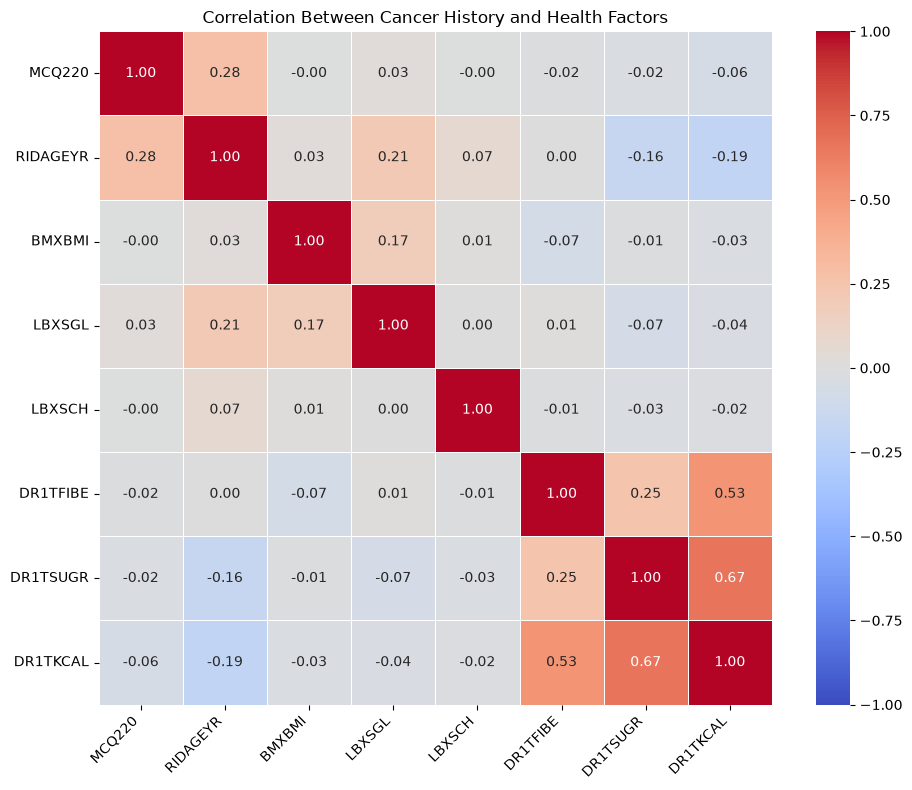

In [44]:
# Correlation Between Cancer History and Health-Related Factors
correlation_columns = [
    "MCQ220",    # Cancer history
    "RIDAGEYR",  # Age
    "BMXBMI",    # BMI
    "LBXSGL",    # Blood glucose
    "LBXSCH",    # Blood total cholesterol
    "DR1TFIBE",  # Dietary fibre
    "DR1TSUGR",  # Dietary sugar
    "DR1TKCAL"   # Total calorie intake
]

correlation_columns = [
    col for col in correlation_columns
    if col in health_data.columns
]

correlation_data = health_data[correlation_columns].copy()

# Encode cancer history: Yes = 1, No = 0
correlation_data["MCQ220"] = correlation_data["MCQ220"].map({
    "Yes": 1,
    "No": 0
})

# Convert selected variables to numeric
for column in correlation_data.columns:
    correlation_data[column] = pd.to_numeric(
        correlation_data[column], errors="coerce"
    )

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Between Cancer History and Health Factors")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

- The correlation heatmap showed very weak linear relationships between cancer history and the selected dietary factors, including dietary fibre, sugar, and total calorie intake.
- This supports the observations from the individual graphs, where dietary distributions largely overlapped between participants with and without a history of cancer.
- Age showed a **comparatively stronger positive correlation with cancer history (0.28)**.

> However, these **results do not establish that dietary factors have no relationship with cancer**, as correlation measures only linear association and does not account for confounding variables.

# Medications Taken

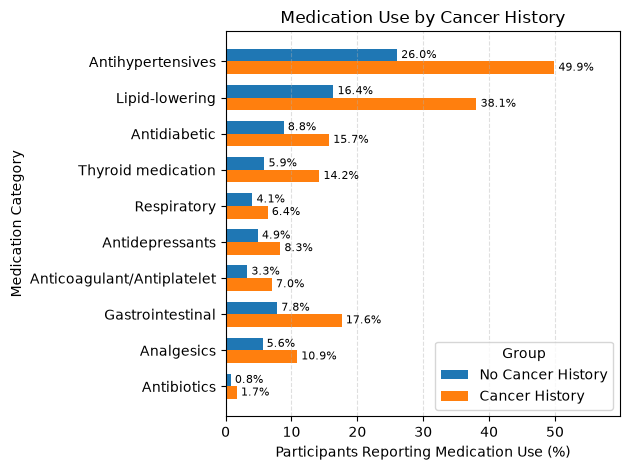

In [45]:
# Medication Use by Cancer History
medication_columns = [
    "Antihypertensive_Use",
    "Lipid_Lowering_Use",
    "Antidiabetic_Use",
    "Thyroid_Medication_Use",
    "Respiratory_Medication_Use",
    "Antidepressant_Use",
    "Anticoagulant_Antiplatelet_Use",
    "GI_Medication_Use",
    "Analgesic_Use",
    "Antibiotic_Use"
]

# Select the required columns
medication_data = health_data[["MCQ220"] + medication_columns].copy()

# Ensure medication indicators are numeric
for column in medication_columns:
    medication_data[column] = pd.to_numeric(medication_data[column], errors="coerce")

# Calculate medication prevalence (%) within each cancer group
def calculate_medication_prevalence(values):
    known = values[values.isin([0, 1])]

    if len(known) == 0:
        return np.nan

    return known.eq(1).mean() * 100


medication_prevalence = (
    medication_data
    .groupby("MCQ220")[medication_columns]
    .agg(calculate_medication_prevalence)
    .reindex(["No", "Yes"])
    .T
)


# Keep the cancer groups in a consistent order
medication_prevalence = medication_prevalence.reindex(
    columns=["No", "Yes"]
)

# Improve medication category labels
medication_labels = {
    "Antihypertensive_Use": "Antihypertensives",
    "Lipid_Lowering_Use": "Lipid-lowering",
    "Antidiabetic_Use": "Antidiabetic",
    "Thyroid_Medication_Use": "Thyroid medication",
    "Respiratory_Medication_Use": "Respiratory",
    "Antidepressant_Use": "Antidepressants",
    "Anticoagulant_Antiplatelet_Use": "Anticoagulant/Antiplatelet",
    "GI_Medication_Use": "Gastrointestinal",
    "Analgesic_Use": "Analgesics",
    "Antibiotic_Use": "Antibiotics"
}

medication_prevalence = medication_prevalence.rename(
    index=medication_labels
)

y = np.arange(len(medication_prevalence))
bar_width = 0.35

# Bars for participants without cancer history
bars_no = plt.barh(
    y - bar_width / 2,
    medication_prevalence["No"],
    height=bar_width,
    label="No Cancer History"
)

# Bars for participants with cancer history
bars_yes = plt.barh(
    y + bar_width / 2,
    medication_prevalence["Yes"],
    height=bar_width,
    label="Cancer History"
)

# Add percentage labels
plt.bar_label(bars_no, fmt="%.1f%%", padding=3, fontsize=8)
plt.bar_label(bars_yes, fmt="%.1f%%", padding=3, fontsize=8)

# Formatting
plt.yticks(y, medication_prevalence.index)
plt.xlabel("Participants Reporting Medication Use (%)")
plt.ylabel("Medication Category")
plt.title("Medication Use by Cancer History")

plt.legend(title="Group")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.gca().invert_yaxis()

# Provide space for percentage labels
max_value = np.nanmax(medication_prevalence.to_numpy())
plt.xlim(0, max_value * 1.2)

plt.tight_layout()
plt.show()

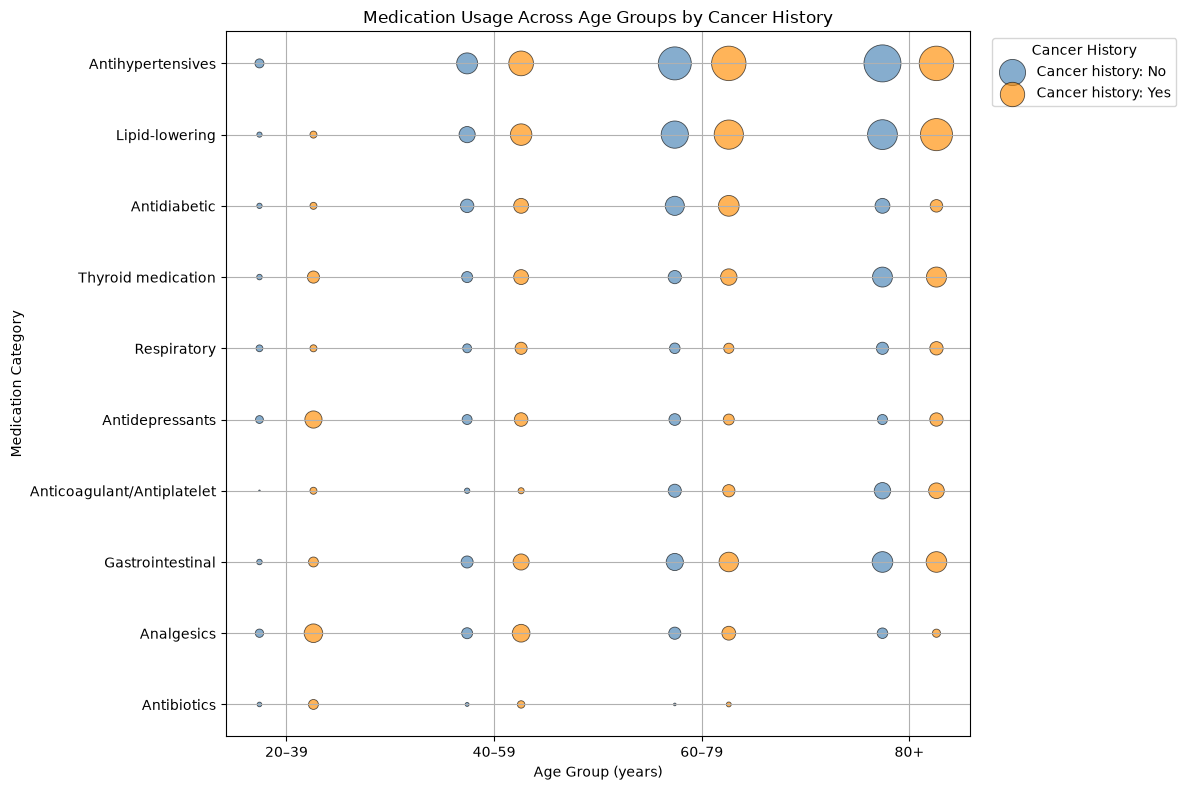

In [46]:
# Bubble Chart: Medication Usage Across Age Groups
medication_columns = [
    "Antihypertensive_Use",
    "Lipid_Lowering_Use",
    "Antidiabetic_Use",
    "Thyroid_Medication_Use",
    "Respiratory_Medication_Use",
    "Antidepressant_Use",
    "Anticoagulant_Antiplatelet_Use",
    "GI_Medication_Use",
    "Analgesic_Use",
    "Antibiotic_Use"
]

medication_labels = {
    "Antihypertensive_Use": "Antihypertensives",
    "Lipid_Lowering_Use": "Lipid-lowering",
    "Antidiabetic_Use": "Antidiabetic",
    "Thyroid_Medication_Use": "Thyroid medication",
    "Respiratory_Medication_Use": "Respiratory",
    "Antidepressant_Use": "Antidepressants",
    "Anticoagulant_Antiplatelet_Use": "Anticoagulant/Antiplatelet",
    "GI_Medication_Use": "Gastrointestinal",
    "Analgesic_Use": "Analgesics",
    "Antibiotic_Use": "Antibiotics"
}

age_data = health_data[["RIDAGEYR", "MCQ220"] + medication_columns].copy()

# Create age groups
age_labels = ["20–39", "40–59", "60–79", "80+"]

age_data["Age Group"] = pd.cut(age_data["RIDAGEYR"], bins=[19, 39, 59, 79, float("inf")], labels=age_labels)
# Convert medication data to long format
medication_long = age_data.melt(
    id_vars=["Age Group", "MCQ220"],
    value_vars=medication_columns,
    var_name="Medication",
    value_name="Reported"
)

medication_long = medication_long.dropna(subset=["Age Group", "MCQ220", "Reported"])

# Calculate prevalence within each age and cancer-history group
def calculate_medication_prevalence(values):
    known = values[values.isin([0, 1])]

    if len(known) == 0:
        return np.nan

    return known.eq(1).mean() * 100


medication_summary = (
    medication_long
    .groupby(
        ["Age Group", "MCQ220", "Medication"],
        observed=True
    )["Reported"]
    .apply(calculate_medication_prevalence)
    .rename("Prevalence")
    .reset_index()
)

medication_summary["Medication"] = (medication_summary["Medication"].map(medication_labels))

# Assign positions for categorical axes
medication_order = list(medication_labels.values())

age_positions = {
    label: i for i, label in enumerate(age_labels)
}

medication_positions = {
    label: i for i, label in enumerate(medication_order)
}

medication_summary["X"] = (medication_summary["Age Group"].astype(str).map(age_positions))

medication_summary["Y"] = (medication_summary["Medication"].map(medication_positions))

# Plot
fig, ax = plt.subplots(figsize=(12, 8))

colors = {
    "No": "steelblue",
    "Yes": "darkorange"
}

# Slight horizontal separation for the two cancer-history groups
offsets = {"No": -0.13, "Yes": 0.13}

for status in ["No", "Yes"]:
    subset = medication_summary[medication_summary["MCQ220"] == status].dropna(subset=["X", "Y", "Prevalence"])

    ax.scatter(subset["X"] + offsets[status], subset["Y"], s=subset["Prevalence"] * 10, color=colors[status], alpha=0.65, edgecolors="black", linewidths=0.6,label=f"Cancer history: {status}")

ax.set_xticks(range(len(age_labels)))
ax.set_xticklabels(age_labels)

ax.set_yticks(range(len(medication_order)))
ax.set_yticklabels(medication_order)

ax.set_xlabel("Age Group (years)")
ax.set_ylabel("Medication Category")
ax.set_title("Medication Usage Across Age Groups by Cancer History")

ax.invert_yaxis()
ax.legend(title="Cancer History", loc="upper left", bbox_to_anchor=(1.02, 1))
plt.grid(True)
plt.tight_layout()
plt.show()

## Observations

- The medication-use heatmap showed a higher prevalence of reported medication use among participants with a history of cancer across all 10 medication categories. 
- The largest differences were observed for antihypertensive medications and lipid-lowering medications.
- **Gastrointestinal** and **Thyroid** medications also showed notable differences between the groups.
- These findings suggest that participants with a cancer history may have a greater burden of coexisting health conditions or healthcare needs
- But from the bubble chart, Antihypertensive medication use is more prevalent among older participants.
- So, the higher use of hypertensive and lipid lowering medications may be explained partily by the higher age

# Statistical Analysis

In [47]:
cancer_data = pd.read_csv("processed_dataset.csv")
cancer_data["MCQ220"] = cancer_data["MCQ220"].map({
    1: "Yes",
    2: "No"
})

## Descriptive Statistical Analysis

In [48]:
# Variables selected for descriptive statistical analysis
continuous_variables = [
    "RIDAGEYR",
    "INDFMPIR",
    "BMXBMI",
    "BMXWAIST",
    "BMXWT",
    "BMXHT",
    "SBP_mean",
    "DBP_mean",
    "BPXPLS",
    "DR1TKCAL",
    "DR1TPROT",
    "DR1TCARB",
    "DR1TSUGR",
    "DR1TFIBE",
    "DR1TTFAT",
    "DR1TSFAT",
    "DR1TCHOL",
    "DR1TALCO",
    "DR1TCAFF",
    "LBXSGL",
    "LBXGH",
    "LBXSCH",
    "LBDHDD",
    "LBDLDL",
    "LBXTR",
    "LBXSATSI",
    "LBXSASSI",
    "LBXSGTSI",
    "LBXSCR",
    "LBXSUA",
    "LBDSALSI",
    "LBXLYPCT",
    "LBXNEPCT",
    "RXDCOUNT"
]

# Verify that all selected variables exist
missing_columns = [
    col for col in continuous_variables
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Columns not found: {missing_columns}")

In [49]:
# Generate descriptive statistics by cancer history
summary_rows = []

for variable in continuous_variables:
    for cancer_status in ["No", "Yes"]:
        values = cancer_data.loc[cancer_data["MCQ220"] == cancer_status,variable].dropna()

        summary_rows.append({
            "Variable": variable,
            "Cancer History": cancer_status,
            "Count": values.count(),
            "Mean": values.mean(),
            "Standard Deviation": values.std(),
            "Median": values.median(),
            "Q1": values.quantile(0.25),
            "Q3": values.quantile(0.75)
        })

descriptive_summary = pd.DataFrame(summary_rows)

display(descriptive_summary.round(2))

,Variable,Cancer History,Count,Mean,Standard Deviation,Median,Q1,Q3
0,RIDAGEYR,No,4646,47.48,16.99,46.00,33.00,61.00
1,RIDAGEYR,Yes,475,64.19,14.56,67.00,56.00,77.00
2,INDFMPIR,No,4646,2.46,1.59,2.12,1.08,3.82
3,INDFMPIR,Yes,475,2.79,1.57,2.23,1.42,4.45
4,BMXBMI,No,4646,29.07,7.06,27.85,24.20,32.40
...,...,...,...,...,...,...,...,...
63,LBXLYPCT,Yes,475,28.50,9.30,28.20,21.90,33.90
64,LBXNEPCT,No,4646,57.84,9.25,58.30,51.90,64.10
65,LBXNEPCT,Yes,475,59.21,9.78,60.00,53.25,65.65
66,RXDCOUNT,No,4645,2.00,2.84,1.00,0.00,3.00


## Observations — Descriptive Statistical Analysis

- The descriptive analysis includes **5,121 participants**, consisting of 4,646 participants without a reported cancer history and 475 participants with a reported cancer history.
- A substantial age difference is observed between the two groups. Participants with a cancer history have a mean age of **64.19 years**, compared with **47.48 years** among participants without a cancer history.
- The median age is 67 years in the cancer-history group and 46 years in the non-cancer group, indicating that participants with a reported cancer history are generally older.
- The mean family income-to-poverty ratio is slightly higher among participants with a cancer history (2.79) than among those without a cancer history (2.46).
- The average prescription medication count is higher in the cancer-history group (**4.16**) compared with the non-cancer group (**2.00**).
- The descriptive statistics for BMI and other health, dietary and laboratory measurements provide information about differences in their central tendencies and variability across the two groups.
- Observation counts vary across variables because missing values are excluded separately for each calculation. For example, the medication count is available for 4,645 participants without cancer history and 474 participants with cancer history.
- Some variables have undergone imputation during preprocessing, so their descriptive statistics include imputed observations.

### Overall Interpretation

The descriptive analysis indicates noticeable differences in age and prescription

## Categorical Descriptive Statistics

In [50]:
categorical_variables = [
    "RIAGENDR",
    "RIDRETH1",
    "SMQ020",
    "SMQ040",
    "ALQ101",
    "ALQ120U",
    "PAQ650",
    "PAQ620",
    "PAQ635",
    "RXDUSE",
    "Antihypertensive_Use",
    "Lipid_Lowering_Use",
    "Antidiabetic_Use",
    "Thyroid_Medication_Use",
    "Respiratory_Medication_Use",
    "Antidepressant_Use",
    "Anticoagulant_Antiplatelet_Use",
    "GI_Medication_Use",
    "Analgesic_Use",
    "Antibiotic_Use"
]

# Verify selected columns
missing_columns = [
    col for col in categorical_variables
    if col not in cancer_data.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

In [51]:
categorical_rows = []

for variable in categorical_variables:
    for cancer_status in ["No", "Yes"]:
        values = cancer_data.loc[cancer_data["MCQ220"] == cancer_status,variable]

        # Include missing responses as a separate category
        counts = (values.astype("string").fillna("Missing").value_counts())

        for category, count in counts.items():
            categorical_rows.append({
                "Variable": variable,
                "Cancer History": cancer_status,
                "Category": category,
                "Count": count,
                "Percentage": count / len(values) * 100
            })

categorical_summary = pd.DataFrame(categorical_rows)


display(categorical_summary.round(2))

,Variable,Cancer History,Category,Count,Percentage
0,RIAGENDR,No,2,2389,51.42
1,RIAGENDR,No,1,2257,48.58
2,RIAGENDR,Yes,2,269,56.63
3,RIAGENDR,Yes,1,206,43.37
4,RIDRETH1,No,3,1899,40.87
...,...,...,...,...,...
113,Antibiotic_Use,No,2,45,0.97
114,Antibiotic_Use,No,1,36,0.77
115,Antibiotic_Use,Yes,0,462,97.26
116,Antibiotic_Use,Yes,1,8,1.68


Medication Indicator
- 0 = No match in selected medication lists.
- 1 = Matching medication identified.
- 2 = Unknown medication classification

- Male/female frequencies sum to 4,646 for the No group and 475 for the Yes group.
- Percentages are calculated within each cancer-history group, including missing responses where applicable.
- Medication values 0, 1, and 2 are correctly kept as separate categories.
- 2 represents unknown medication classification, while 0 means no match in your selected medication list.

## Normality and Assumption Testing

The Shapiro-Wilk test will be used to evaluate whether the observations in each cancer-history group follow a normal distribution.

The test hypotheses are:

Null hypothesis (H₀): The observations follow a normal distribution.

Alternative hypothesis (H₁): The observations do not follow a normal distribution.

In [52]:
from scipy.stats import shapiro

normality_variables = [
    col for col in continuous_variables
    if col != "RXDCOUNT"
]

normality_results = []

for variable in normality_variables:
    for cancer_status in ["No", "Yes"]:

        values = cancer_data.loc[cancer_data["MCQ220"] == cancer_status, variable].dropna()

        if len(values) < 3:
            continue

        statistic, p_value = shapiro(values)

        normality_results.append({
            "Variable": variable,
            "Cancer History": cancer_status,
            "Sample Size": len(values),
            "Shapiro Statistic": statistic,
            "P-Value": p_value,
            "Normality": (
                "Approximately Normal"
                if p_value >= 0.05
                else "Non-Normal"
            )
        })

normality_summary = pd.DataFrame(normality_results)
display(normality_summary.round(5))

,Variable,Cancer History,Sample Size,Shapiro Statistic,P-Value,Normality
0,RIDAGEYR,No,4646,0.96241,0.00000,Non-Normal
1,RIDAGEYR,Yes,475,0.89973,0.00000,Non-Normal
2,INDFMPIR,No,4646,0.90213,0.00000,Non-Normal
3,INDFMPIR,Yes,475,0.89510,0.00000,Non-Normal
4,BMXBMI,No,4646,0.92370,0.00000,Non-Normal
...,...,...,...,...,...,...
61,LBDSALSI,Yes,475,0.98374,0.00004,Non-Normal
62,LBXLYPCT,No,4646,0.99285,0.00000,Non-Normal
63,LBXLYPCT,Yes,475,0.96128,0.00000,Non-Normal
64,LBXNEPCT,No,4646,0.99569,0.00000,Non-Normal


In [53]:
normality_summary[normality_summary["Normality"] != "Non-Normal"]

,Variable,Cancer History,Sample Size,Shapiro Statistic,P-Value,Normality
11,BMXHT,Yes,475,0.995758,0.229051,Approximately Normal
47,LBDLDL,Yes,233,0.990825,0.149835,Approximately Normal
59,LBXSUA,Yes,475,0.996348,0.350817,Approximately Normal


In [54]:
normality_summary.loc[
    normality_summary["Variable"].isin(["BMXHT", "LBDLDL", "LBXSUA"]),
    [
        "Variable",
        "Cancer History",
        "Sample Size",
        "Shapiro Statistic",
        "P-Value",
        "Normality"
    ]
].sort_values(["Variable", "Cancer History"])

,Variable,Cancer History,Sample Size,Shapiro Statistic,P-Value,Normality
10,BMXHT,No,4646,0.995476,8.340622e-11,Non-Normal
11,BMXHT,Yes,475,0.995758,2.290510e-01,Approximately Normal
46,LBDLDL,No,2170,0.969688,5.373862e-21,Non-Normal
47,LBDLDL,Yes,233,0.990825,1.498347e-01,Approximately Normal
58,LBXSUA,No,4646,0.984378,2.884816e-22,Non-Normal
59,LBXSUA,Yes,475,0.996348,3.508171e-01,Approximately Normal


In [55]:
# Identify variables that satisfy normality in both groups
normal_variables_both = (
    normality_summary
    .groupby("Variable")["P-Value"]
    .apply(lambda p: (p >= 0.05).all())
)

normal_variables_both = normal_variables_both[
    normal_variables_both
].index.tolist()

print("Variables approximately normal in both groups:")
print(normal_variables_both)

print("\nTotal:", len(normal_variables_both))

Variables approximately normal in both groups:
[]

Total: 0


- No variable satisfies the normality criterion in both groups.
- Some variables are approximately normal in the cancer-history group, but their corresponding No-cancer groups are non-normal.
- The large sample sizes make Shapiro-Wilk sensitive to relatively small deviations from normality.
- Therefore, we should also consider distribution plots and sample sizes when selecting statistical tests.

## Homogeneity of Variances

Levene's test is used to determine whether the variability of continuous health, demographic, dietary and laboratory measurements differs between participants with and without a reported cancer history.

Hypotheses:

H₀: The variances of the two groups are equal.

H₁: The variances of the two groups are unequal.

A significance level of 0.05 is used. Median-based Levene testing is selected because it is more robust to departures from normality.

In [56]:
import scipy.stats as stats
variance_results = []

for variable in normality_variables:
    no_cancer = cancer_data.loc[cancer_data["MCQ220"] == "No", variable].dropna().to_numpy()
    cancer = cancer_data.loc[cancer_data["MCQ220"] == "Yes", variable].dropna().to_numpy()

    if len(no_cancer) < 2 or len(cancer) < 2:
        continue

    statistic, p_value = stats.levene(no_cancer,cancer,center="median")

    variance_results.append({
        "Variable": variable,
        "Levene Statistic": statistic,
        "P-Value": p_value,
        "Conclusion": (
            "Unequal Variances"
            if p_value < 0.05
            else "Equal Variances"
        )
    })

variance_summary = pd.DataFrame(variance_results)

display(variance_summary.round(5))

,Variable,Levene Statistic,P-Value,Conclusion
0,RIDAGEYR,46.03946,0.00000,Unequal Variances
1,INDFMPIR,1.26694,0.26039,Equal Variances
2,BMXBMI,1.82188,0.17715,Equal Variances
3,BMXWAIST,3.04302,0.08115,Equal Variances
4,BMXWT,1.13485,0.28679,Equal Variances
5,BMXHT,0.11444,0.73516,Equal Variances
6,SBP_mean,9.22134,0.00240,Unequal Variances
7,DBP_mean,0.00935,0.92298,Equal Variances
8,BPXPLS,0.83363,0.36127,Equal Variances
9,DR1TKCAL,12.38483,0.00044,Unequal Variances


## Observation

At a significance level of 0.05:

12 variables showed statistically significant evidence of unequal variances.

21 variables did not show statistically significant evidence of unequal variances.

Unequal variances were observed for variables including age (RIDAGEYR), mean systolic blood pressure (SBP_mean), dietary energy intake (DR1TKCAL), protein intake (DR1TPROT), and several lipid and dietary measurements.

These results indicate that variance equality should not be assumed for every variable

## Correlation Analysis

Spearman's rank correlation is used because many variables did not satisfy the Shapiro–Wilk normality test. It measures monotonic relationships and does not require normally distributed variables.

H₀: There is no monotonic association between the two variables.

H₁: There is a monotonic association between the two variables.

Significance level: α = 0.05.

In [57]:
# Select continuous variables and exclude variables with no useful variation
correlation_variables = [
    col for col in continuous_variables
    if col in cancer_data.columns
    and cancer_data[col].nunique(dropna=True) > 1
]

correlation_matrix = cancer_data[correlation_variables].corr(method="spearman")

display(correlation_matrix.round(2))

,RIDAGEYR,INDFMPIR,BMXBMI,BMXWAIST,BMXWT,BMXHT,SBP_mean,DBP_mean,BPXPLS,DR1TKCAL,...,LBXTR,LBXSATSI,LBXSASSI,LBXSGTSI,LBXSCR,LBXSUA,LBDSALSI,LBXLYPCT,LBXNEPCT,RXDCOUNT
RIDAGEYR,1.00,0.08,0.07,0.22,-0.02,-0.15,0.43,0.01,-0.17,-0.19,...,0.13,-0.04,0.09,0.10,0.23,0.12,-0.23,-0.14,0.07,0.54
INDFMPIR,0.08,1.00,-0.07,-0.06,-0.00,0.12,-0.02,0.02,-0.08,0.04,...,-0.04,0.03,0.04,-0.04,0.07,0.03,0.11,-0.00,-0.01,0.02
BMXBMI,0.07,-0.07,1.00,0.91,0.86,-0.02,0.19,0.14,0.10,-0.02,...,0.27,0.19,0.03,0.23,0.03,0.26,-0.28,-0.05,0.07,0.21
BMXWAIST,0.22,-0.06,0.91,1.00,0.88,0.16,0.25,0.14,0.10,0.00,...,0.32,0.23,0.06,0.28,0.12,0.33,-0.27,-0.12,0.11,0.29
BMXWT,-0.02,-0.00,0.86,0.88,1.00,0.46,0.17,0.17,0.06,0.13,...,0.24,0.26,0.08,0.26,0.23,0.37,-0.15,-0.07,0.05,0.13
BMXHT,-0.15,0.12,-0.02,0.16,0.46,1.00,0.02,0.11,-0.05,0.31,...,0.01,0.22,0.12,0.15,0.45,0.30,0.21,-0.04,-0.02,-0.09
SBP_mean,0.43,-0.02,0.19,0.25,0.17,0.02,1.00,0.40,-0.04,-0.04,...,0.16,0.10,0.13,0.22,0.16,0.19,-0.09,-0.08,0.03,0.25
DBP_mean,0.01,0.02,0.14,0.14,0.17,0.11,0.40,1.00,0.12,0.05,...,0.16,0.15,0.07,0.20,0.01,0.09,0.01,0.04,-0.04,-0.04
BPXPLS,-0.17,-0.08,0.10,0.10,0.06,-0.05,-0.04,0.12,1.00,-0.02,...,0.07,0.05,-0.02,0.09,-0.15,-0.03,-0.03,-0.08,0.12,-0.01
DR1TKCAL,-0.19,0.04,-0.02,0.00,0.13,0.31,-0.04,0.05,-0.02,1.00,...,-0.00,0.12,0.07,0.05,0.10,0.06,0.09,-0.02,-0.01,-0.16


In [58]:
import numpy as np

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))

# Convert correlation matrix into pairs
correlation_pairs = (upper_triangle.stack().reset_index())

correlation_pairs.columns = [
    "Variable 1", "Variable 2", "Spearman Correlation"
]

# Sort by correlation value
correlation_pairs = correlation_pairs.sort_values("Spearman Correlation", ascending=False)

print("Top 10 strongest positive correlations:")
display(correlation_pairs.head(10).round(3))

print("Top 10 strongest negative correlations:")
display(correlation_pairs.sort_values("Spearman Correlation", ascending=True).head(10).round(3))

print("Highest correlation:")
display(correlation_pairs.iloc[[0]].round(3))

print("Lowest correlation:")
display(correlation_pairs.iloc[correlation_pairs["Spearman Correlation"].argmin():][:1].round(3))


Top 10 strongest positive correlations:


,Variable 1,Variable 2,Spearman Correlation
491,DR1TTFAT,DR1TSFAT,0.917
71,BMXBMI,BMXWAIST,0.906
737,LBXSCH,LBDLDL,0.890
106,BMXWAIST,BMXWT,0.876
320,DR1TKCAL,DR1TTFAT,0.871
317,DR1TKCAL,DR1TCARB,0.863
72,BMXBMI,BMXWT,0.860
386,DR1TCARB,DR1TSUGR,0.814
321,DR1TKCAL,DR1TSFAT,0.805
316,DR1TKCAL,DR1TPROT,0.760


Top 10 strongest negative correlations:


,Variable 1,Variable 2,Spearman Correlation
1086,LBXLYPCT,LBXNEPCT,-0.928
772,LBDHDD,LBXTR,-0.497
158,BMXWT,LBDHDD,-0.376
124,BMXWAIST,LBDHDD,-0.367
90,BMXBMI,LBDHDD,-0.312
777,LBDHDD,LBXSUA,-0.289
98,BMXBMI,LBDSALSI,-0.279
132,BMXWAIST,LBDSALSI,-0.268
192,BMXHT,LBDHDD,-0.232
773,LBDHDD,LBXSATSI,-0.229


Highest correlation:


,Variable 1,Variable 2,Spearman Correlation
491,DR1TTFAT,DR1TSFAT,0.917


Lowest correlation:


,Variable 1,Variable 2,Spearman Correlation
1086,LBXLYPCT,LBXNEPCT,-0.928


### Observations
- Strongest positive correlation: Total fat intake (DR1TTFAT) and saturated fat intake (DR1TSFAT) showed a strong positive correlation ((\rho = 0.917)).

- Anthropometric measurements: BMI (BMXBMI) and waist circumference (BMXWAIST) were strongly positively correlated ((\rho = 0.906)).

- Blood lipid measurements: Total cholesterol (LBXSCH) and LDL cholesterol (LBDLDL) showed a strong positive correlation ((\rho = 0.890)).

- Strongest negative correlation: Lymphocyte percentage (LBXLYPCT) and neutrophil percentage (LBXNEPCT) showed a strong negative correlation ((\rho = -0.928)).

- Dietary energy intake (DR1TKCAL) was also strongly positively correlated with total fat and carbohydrate intake. These relationships are plausible because the measurements are related components of diet or body composition.

## Chi-Square Test of Independence

The Chi-square test of independence determines whether a statistically significant association exists between cancer history (MCQ220) and categorical variables such as sex, race/ethnicity, smoking, alcohol use, physical activity, and medication use.

H₀: Cancer history and the categorical variable are independent.

H₁: Cancer history and the categorical variable are associated.

Significance level: α = 0.05.

In [59]:

from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

chi_square_results = []

for variable in categorical_variables:
    contingency_table = pd.crosstab(cancer_data[variable],cancer_data["MCQ220"])

    # Remove missing categories and skip unsuitable tables
    contingency_table = contingency_table.loc[contingency_table.index.notna()]

    if contingency_table.shape[0] < 2 or contingency_table.shape[1] < 2:
        continue

    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum()
    min_dimension = min(contingency_table.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dimension))

    chi_square_results.append({
        "Variable": variable,
        "Chi-Square": chi2,
        "Degrees of Freedom": dof,
        "P-Value": p_value,
        "Cramers V": cramers_v,
        "Minimum Expected Frequency": expected.min(),
        "Cells Expected < 5": (expected < 5).sum(),
        "Conclusion": (
            "Significant Association"
            if p_value < 0.05
            else "No Significant Association"
        )
    })

chi_square_summary = pd.DataFrame(chi_square_results)

display(chi_square_summary.sort_values("P-Value").round(4))

,Variable,Chi-Square,Degrees of Freedom,P-Value,Cramers V,Minimum Expected Frequency,Cells Expected < 5,Conclusion
9,RXDUSE,215.7407,2,0.0000,0.2053,0.1855,2,Significant Association
1,RIDRETH1,166.4562,4,0.0000,0.1803,42.4819,0,Significant Association
11,Lipid_Lowering_Use,134.1138,2,0.0000,0.1618,4.0812,1,Significant Association
10,Antihypertensive_Use,120.2003,2,0.0000,0.1532,3.2464,1,Significant Association
17,GI_Medication_Use,51.5764,2,0.0000,0.1004,4.4523,1,Significant Association
13,Thyroid_Medication_Use,47.8390,2,0.0000,0.0967,4.4523,1,Significant Association
6,PAQ650,29.0608,1,0.0000,0.0753,106.1121,0,Significant Association
2,SMQ020,23.0959,1,0.0000,0.0672,207.0299,0,Significant Association
12,Antidiabetic_Use,23.7399,2,0.0000,0.0681,4.1740,1,Significant Association
3,SMQ040,22.8730,2,0.0000,0.1012,23.1438,0,Significant Association


### Observation

Statistically significant associations were observed for 15 of the 20 categorical variables tested. The strongest associations by Cramér's V included:

- Medication use (RXDUSE): Cramér's V = 0.205.
- Race/ethnicity (RIDRETH1): Cramér's V = 0.180.
- Lipid-lowering medication use: Cramér's V = 0.162.
- Antihypertensive medication use: Cramér's V = 0.153.
- Gastrointestinal medication use: Cramér's V = 0.100.

Other statistically significant associations included thyroid medication use, physical activity (PAQ650, PAQ635), smoking variables (SMQ020, SMQ040), antidiabetic medication use, analgesic use, anticoagulant/antiplatelet use, antidepressant use, and sex (RIAGENDR).

No statistically significant association was detected for respiratory medication use, antibiotic use, alcohol variables (ALQ120U, ALQ101), or physical activity variable PAQ620 (p ≥ 0.05).

## Comparison of Continuous Variables Between Cancer-History Groups

The Mann–Whitney U test is used to compare the distributions of continuous variables between two independent groups: participants with and without a reported cancer history.

This non-parametric test is suitable for this analysis because many continuous variables did not satisfy the Shapiro–Wilk normality test.

- H₀: The distributions of the two groups are identical.
- H₁: The distributions of the two groups differ.

Significance level: α = 0.05.

In [60]:
from scipy.stats import mannwhitneyu
import numpy as np
import pandas as pd

mann_whitney_results = []

for variable in continuous_variables:
    no_cancer = cancer_data.loc[cancer_data["MCQ220"] == "No", variable].dropna().to_numpy()

    cancer = cancer_data.loc[cancer_data["MCQ220"] == "Yes", variable].dropna().to_numpy()

    if len(no_cancer) == 0 or len(cancer) == 0:
        continue

    u_statistic, p_value = mannwhitneyu(no_cancer,cancer,alternative="two-sided")

    # Rank-biserial correlation effect size
    effect_size = (2 * u_statistic / (len(no_cancer) * len(cancer))) - 1

    mann_whitney_results.append({
        "Variable": variable,
        "No Cancer Median": np.median(no_cancer),
        "Cancer Median": np.median(cancer),
        "U Statistic": u_statistic,
        "P-Value": p_value,
        "Rank-Biserial Correlation": effect_size,
        "Conclusion": (
            "Significant Difference"
            if p_value < 0.05
            else "No Significant Difference"
        )
    })

mann_whitney_summary = pd.DataFrame(mann_whitney_results)

display(mann_whitney_summary.sort_values("P-Value").round(4))

,Variable,No Cancer Median,Cancer Median,U Statistic,P-Value,Rank-Biserial Correlation,Conclusion
0,RIDAGEYR,46.0000,67.00,508092.0,0.0000,-0.5395,Significant Difference
33,RXDCOUNT,1.0000,3.00,609125.5,0.0000,-0.4467,Significant Difference
20,LBXGH,5.5000,5.70,886661.5,0.0000,-0.1964,Significant Difference
18,DR1TCAFF,93.0000,130.00,793385.0,0.0000,-0.1524,Significant Difference
31,LBXLYPCT,30.1000,28.20,1263905.0,0.0000,0.1454,Significant Difference
10,DR1TPROT,75.2250,66.44,1072747.0,0.0000,0.1460,Significant Difference
6,SBP_mean,119.3333,124.00,962646.5,0.0000,-0.1276,Significant Difference
7,DBP_mean,70.6667,68.00,1243416.5,0.0000,0.1269,Significant Difference
19,LBXSGL,94.0000,98.00,965788.0,0.0000,-0.1247,Significant Difference
1,INDFMPIR,2.1200,2.23,966639.0,0.0000,-0.1240,Significant Difference


### Observations

- Age (RIDAGEYR): Median age was 67 years in the cancer-history group versus 46 years in the group without cancer history. This was the strongest observed group difference (rank-biserial correlation = −0.540).
- Medication count (RXDCOUNT): The median medication count was 3 versus 1, respectively (rank-biserial correlation = −0.447).
- Glycated haemoglobin (LBXGH): Median values were 5.7 versus 5.5.
- Systolic blood pressure (SBP_mean): Median values were 124 versus 119.33.
- Waist circumference (BMXWAIST): Median values were 101.1 versus 97.3.
- Dietary intake: Median calorie and protein intake was lower in the cancer-history group, while caffeine intake was higher.

At the nominal 0.05 significance level, 21 of the 34 continuous variables showed statistically significant differences. The remaining 13 did not show statistically significant differences.

The strongest differences were observed for age and medication count. Many other effect sizes were relatively small, indicating that statistical significance does not necessarily imply a large difference between groups.


## Multiple Testing Correction: Mann–Whitney U Tests

Multiple hypothesis tests increase the probability of obtaining false-positive
results. The Benjamini–Hochberg procedure is used to control the False
Discovery Rate (FDR).

Adjusted p-values will help identify which differences between participants
with and without a reported cancer history remain statistically significant
after accounting for multiple comparisons. We use a significance level of 0.05.

In [61]:
from statsmodels.stats.multitest import multipletests

mann_whitney_summary["Adjusted P-Value"] = multipletests(mann_whitney_summary["P-Value"],method="fdr_bh")[1]

mann_whitney_summary["Significant After Correction"] = (mann_whitney_summary["Adjusted P-Value"] < 0.05)

display(mann_whitney_summary.sort_values("Adjusted P-Value").round(4))

,Variable,No Cancer Median,Cancer Median,U Statistic,P-Value,Rank-Biserial Correlation,Conclusion,Adjusted P-Value,Significant After Correction
0,RIDAGEYR,46.0000,67.00,508092.0,0.0000,-0.5395,Significant Difference,0.0000,True
33,RXDCOUNT,1.0000,3.00,609125.5,0.0000,-0.4467,Significant Difference,0.0000,True
20,LBXGH,5.5000,5.70,886661.5,0.0000,-0.1964,Significant Difference,0.0000,True
18,DR1TCAFF,93.0000,130.00,793385.0,0.0000,-0.1524,Significant Difference,0.0000,True
31,LBXLYPCT,30.1000,28.20,1263905.0,0.0000,0.1454,Significant Difference,0.0000,True
10,DR1TPROT,75.2250,66.44,1072747.0,0.0000,0.1460,Significant Difference,0.0000,True
7,DBP_mean,70.6667,68.00,1243416.5,0.0000,0.1269,Significant Difference,0.0000,True
6,SBP_mean,119.3333,124.00,962646.5,0.0000,-0.1276,Significant Difference,0.0000,True
19,LBXSGL,94.0000,98.00,965788.0,0.0000,-0.1247,Significant Difference,0.0000,True
1,INDFMPIR,2.1200,2.23,966639.0,0.0000,-0.1240,Significant Difference,0.0000,True


### Observations

- 19 of the 34 variables remain statistically significant at an adjusted p-value threshold of 0.05.
- Age (RIDAGEYR): Median was 67 years in the cancer-history group versus 46 years in the no-cancer-history group. This was the strongest observed difference.
- Medication count (RXDCOUNT): Median was 3 versus 1, respectively.
- Other significant differences: Included glycated hemoglobin (LBXGH), caffeine intake (DR1TCAFF), protein intake (DR1TPROT), systolic and diastolic blood pressure, glucose, waist circumference, and several blood measurements.
- No longer significant after correction: Uric acid (LBXSUA) and total fat intake (DR1TTFAT) had unadjusted p-values below 0.05 but adjusted p-values above 0.05.

In [62]:
from statsmodels.stats.multitest import multipletests

chi_square_summary["Adjusted P-Value"] = multipletests(chi_square_summary["P-Value"],method="fdr_bh")[1]

chi_square_summary["Significant After Correction"] = (chi_square_summary["Adjusted P-Value"] < 0.05)

display(chi_square_summary.sort_values("Adjusted P-Value").round(4))

,Variable,Chi-Square,Degrees of Freedom,P-Value,Cramers V,Minimum Expected Frequency,Cells Expected < 5,Conclusion,Adjusted P-Value,Significant After Correction
9,RXDUSE,215.7407,2,0.0000,0.2053,0.1855,2,Significant Association,0.0000,True
1,RIDRETH1,166.4562,4,0.0000,0.1803,42.4819,0,Significant Association,0.0000,True
11,Lipid_Lowering_Use,134.1138,2,0.0000,0.1618,4.0812,1,Significant Association,0.0000,True
10,Antihypertensive_Use,120.2003,2,0.0000,0.1532,3.2464,1,Significant Association,0.0000,True
17,GI_Medication_Use,51.5764,2,0.0000,0.1004,4.4523,1,Significant Association,0.0000,True
13,Thyroid_Medication_Use,47.8390,2,0.0000,0.0967,4.4523,1,Significant Association,0.0000,True
6,PAQ650,29.0608,1,0.0000,0.0753,106.1121,0,Significant Association,0.0000,True
2,SMQ020,23.0959,1,0.0000,0.0672,207.0299,0,Significant Association,0.0000,True
12,Antidiabetic_Use,23.7399,2,0.0000,0.0681,4.1740,1,Significant Association,0.0000,True
3,SMQ040,22.8730,2,0.0000,0.1012,23.1438,0,Significant Association,0.0000,True


### Observations
After Benjamini–Hochberg correction, 15 of the 20 categorical variables remain statistically significant at an adjusted \(p < 0.05\).

Interpretation of results
- Strongest association: RXDUSE (prescription medication use), with Cramér’s V = 0.2053.
- Other notable associations: RIDRETH1 (race/ethnicity), lipid-lowering medication use, antihypertensive medication use, and GI medication use.
- Smaller associations: Sex (RIAGENDR) remains statistically significant after correction, but its Cramér’s V is only 0.0296.
- Not significant after correction: Respiratory medication use, antibiotic use, ALQ120U, PAQ620, and ALQ101.

## Statistical Analysis Summary

## 1. Descriptive Statistical Analysis

The dataset contains 5,121 participants, of whom 4,646 reported no history of cancer and 475 reported a history of cancer.

The descriptive analysis revealed the following differences:

- **Age:** Participants with a reported cancer history had a mean age of 64.19 years and a median age of 67 years. In comparison, participants without a cancer history had a mean age of 47.48 years and a median age of 46 years.
- **Prescription medication count:** The mean medication count was higher in the cancer-history group (4.16) than in the no-cancer-history group (2.00).
- **Income-to-poverty ratio:** The mean ratio was slightly higher in the cancer-history group (2.79) compared with the no-cancer-history group (2.46).
- Other health, dietary, and laboratory measurements showed varying degrees of overlap between the two groups.

These observations indicate that the two groups differ in several characteristics, particularly age and medication usage.

## 2. Normality Assessment — Shapiro–Wilk Test

The Shapiro–Wilk test was performed on 33 continuous variables separately for both cancer-history groups.

- No continuous variable satisfied the normality criterion in both groups.
- A few variables, including height, LDL cholesterol, and uric acid, were approximately normally distributed in the cancer-history group but were non-normal in the no-cancer-history group.
- The large sample sizes make the Shapiro–Wilk test sensitive to even small deviations from normality.

Therefore, non-parametric statistical techniques were considered appropriate for comparing the two independent groups.

## 3. Homogeneity of Variances — Levene's Test


Median-based Levene's testing was performed to examine whether the variances differed between the two groups.

- **12 variables** showed statistically significant evidence of unequal variances.
- **21 variables** did not show statistically significant evidence of unequal variances.

Unequal variances were observed in variables such as age, mean systolic blood pressure, calorie intake, protein intake, carbohydrate intake, total fat intake, saturated fat intake, cholesterol intake, caffeine intake, total cholesterol, HDL cholesterol, and lymphocyte percentage.

These findings indicate that equal variances should not automatically be assumed when comparing the two groups.

## 4. Correlation Analysis — Spearman's Rank Correlation

Investigated monotonic relationships between continuous variables.

The strongest positive correlations included:

- Total fat intake and saturated fat intake: **ρ = 0.917**
- BMI and waist circumference: **ρ = 0.906**
- Total cholesterol and LDL cholesterol: **ρ = 0.890**
- Waist circumference and body weight: **ρ = 0.876**
- Total calorie intake and total fat intake: **ρ = 0.871**
- Total calorie intake and carbohydrate intake: **ρ = 0.863**

The strongest negative correlation was observed between lymphocyte percentage and neutrophil percentage (**ρ = -0.928**).

Other negative correlations included HDL cholesterol with triglycerides (ρ = -0.497) and HDL cholesterol with body weight (ρ = -0.376).

These findings indicate that several health and dietary measurements are strongly related to one another. 
However, the correlation analysis reports correlation coefficients without individual significance tests. Therefore, these relationships should be interpreted descriptively.


## 5. Chi-Square Test of Independence

Investigated associations between cancer history and 20 categorical variables.

After applying the Benjamini–Hochberg correction:

- **15 of the 20 variables** remained statistically significant at an adjusted p-value below 0.05.
- The strongest observed association was for prescription medication use (RXDUSE), with Cramér's V = 0.2053.
- Other notable associations included race/ethnicity (RIDRETH1), lipid-lowering medication use, antihypertensive medication use, and gastrointestinal medication use.
- Smoking variables, physical activity variables, antidiabetic medication use, thyroid medication use, analgesic use, anticoagulant/antiplatelet use, antidepressant use, and sex also remained statistically significant.
- Respiratory medication use, antibiotic use, ALQ120U, PAQ620, and ALQ101 did not remain statistically significant after correction.

The effect sizes varied across the significant variables. For example, sex showed a statistically significant association, but its Cramér's V was relatively small (0.0296).

Some contingency tables had low expected cell frequencies. In particular, RXDUSE had a minimum expected frequency of 0.1855, indicating that its chi-square approximation may be unreliable. These results should be interpreted cautiously.


## 6. Mann–Whitney U Test


The Mann–Whitney U test was used to compare continuous-variable distributions between participants with and without a reported cancer history.

Before multiple-testing correction, 21 of the 34 variables showed statistically significant differences.

After applying the Benjamini–Hochberg correction:

- **19 of the 34 variables** remained statistically significant at an adjusted p-value below 0.05.
- Age showed the strongest difference, with median values of 67 years in the cancer-history group and 46 years in the no-cancer-history group. Its rank-biserial correlation was -0.5395.
- Prescription medication count was also substantially different, with median values of 3 and 1, respectively, and a rank-biserial correlation of -0.4467.
- Other significant variables included HbA1c, caffeine intake, protein intake, systolic and diastolic blood pressure, blood glucose, income-to-poverty ratio, creatinine, albumin, calorie intake, waist circumference, neutrophil percentage, carbohydrate intake, dietary cholesterol, pulse rate, and HDL cholesterol.

Uric acid and total fat intake were significant before correction but did not remain significant after multiple-testing adjustment.

## 7. Overall Statistical Findings


The statistical analysis identified several differences and associations between participants with and without a reported cancer history.

The most prominent finding was the difference in age between the two groups. Participants reporting a history of cancer were considerably older and also had a higher prescription medication count.

The chi-square analysis identified associations involving demographic characteristics, smoking, physical activity, and medication use. The Mann–Whitney U analysis identified differences in several clinical, dietary, demographic, and laboratory measurements.

The correlation analysis also demonstrated strong relationships between several continuous variables, particularly measurements related to body composition, dietary intake, and blood chemistry.

Overall, these findings suggest that reported cancer history is associated with multiple demographic and health-related characteristics in the analyzed sample. However, the findings do not establish that these characteristics cause cancer or independently increase cancer risk. Further interpretation must account for potential confounding, missing and imputed values, self-reported cancer history, and limitations in some chi-square test assumptions.